### 1. Understanding the Dataset
Activity: Dataset Exploration

In [721]:
!pip install xgboost

In [723]:
!pip install shap
!pip install lime


In [635]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import kurtosis, skew
from sklearn.preprocessing import OrdinalEncoder,OneHotEncoder
from sklearn.impute import SimpleImputer
import numpy as np
from sklearn.preprocessing import StandardScaler
import warnings
from sklearn.exceptions import ConvergenceWarning

# ignore teh warning
warnings.filterwarnings("ignore", category=ConvergenceWarning)


# Load the dataset
df = pd.read_csv('final_project_dataset_complete.csv')

# Display basic information
print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())
print("\nLast 5 rows:")
display(df.tail())
        
# Check data types
print("\nData types:")
print(df.dtypes)

# Summary statistics
print("\nSummary statistics for numerical features:")
display(df.describe())

# Check the unique vlues for category_1, category_2, number of the values for each one
print("\nUnique values for category_1\n",df["category_1"].unique())
print("\nHow many times each one has been used",df["category_1"].value_counts())
print("\nUnique values for category_2\n",df["category_2"].unique())
print("\nHow many times each one has been used",df["category_2"].value_counts())

# Check for missing values
print("\nMissing values per column:")
print(df.isnull().sum())

Dataset shape: (9000, 11)

First 5 rows:


,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,category_1,category_2,target
0,0.496714,1.146509,-0.648521,0.833005,0.784920,-2.209437,-1.300105,-2.242241,Above Average,Region C,1
1,-0.138264,-0.061846,NaN,0.403768,0.704674,-2.498565,-1.339227,-1.942298,Below Average,Region A,0
2,0.647689,1.395115,-0.764126,1.708266,-0.250029,1.956259,1.190238,1.503559,High,Region C,1
3,1.523030,2.657560,-2.461653,2.649051,0.882201,3.445638,2.120913,3.409035,High,Region B,1
4,-0.234153,-0.499391,0.576097,-0.441656,0.610601,0.211425,0.935759,-0.401463,Below Average,Region C,0



Last 5 rows:


,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,category_1,category_2,target
8995,0.101630,0.400250,NaN,-0.019412,-0.063150,0.077627,0.540975,-0.169030,Above Average,Region A,0
8996,1.167218,2.177774,-1.716067,1.994835,0.350043,-0.544915,0.089050,-0.944220,High,Region C,1
8997,1.588447,3.333945,-2.615488,3.476880,-0.933276,2.027658,0.239583,1.951491,High,Region C,1
8998,-0.684987,-1.599835,1.063341,-1.252109,-0.724001,2.228943,0.989794,1.936476,Low,Region B,0
8999,0.801182,1.808647,-1.383917,1.841776,0.702840,-0.339918,-0.027882,-0.462744,High,Region C,1



Data types:
feature_1     float64
feature_2     float64
feature_3     float64
feature_4     float64
feature_5     float64
feature_6     float64
feature_7     float64
feature_8     float64
category_1     object
category_2     object
target          int64
dtype: object

Summary statistics for numerical features:


,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,target
count,9000.000000,9000.000000,8600.000000,9000.000000,9000.000000,8500.000000,9000.000000,9000.000000,9000.000000
mean,0.000427,0.003349,0.003235,-0.008481,-0.002177,-0.006447,0.000592,0.003348,0.475444
std,1.241318,2.508324,1.542901,2.061784,0.577415,1.981615,1.075064,2.043643,0.499424
min,-18.665400,-37.852816,-6.676680,-8.190124,-0.999791,-8.590782,-4.422265,-9.474989,0.000000
25%,-0.680062,-1.382610,-1.022085,-1.399928,-0.502614,-1.329040,-0.700078,-1.356620,0.000000
50%,-0.003938,-0.016698,0.005196,-0.019541,0.001695,-0.003137,-0.000097,-0.007584,0.000000
75%,0.680513,1.380228,1.038571,1.394151,0.497004,1.324897,0.731942,1.402024,1.000000
max,21.934496,47.603454,6.203055,8.189001,0.999914,6.803751,3.857219,7.572578,1.000000



Unique values for category_1
 ['Above Average' 'Below Average' 'High' 'Low']

How many times each one has been used category_1
Low              2802
High             2763
Above Average    1727
Below Average    1708
Name: count, dtype: int64

Unique values for category_2
 ['Region C' 'Region A' 'Region B']

How many times each one has been used category_2
Region B    3618
Region A    3551
Region C    1831
Name: count, dtype: int64

Missing values per column:
feature_1       0
feature_2       0
feature_3     400
feature_4       0
feature_5       0
feature_6     500
feature_7       0
feature_8       0
category_1      0
category_2      0
target          0
dtype: int64


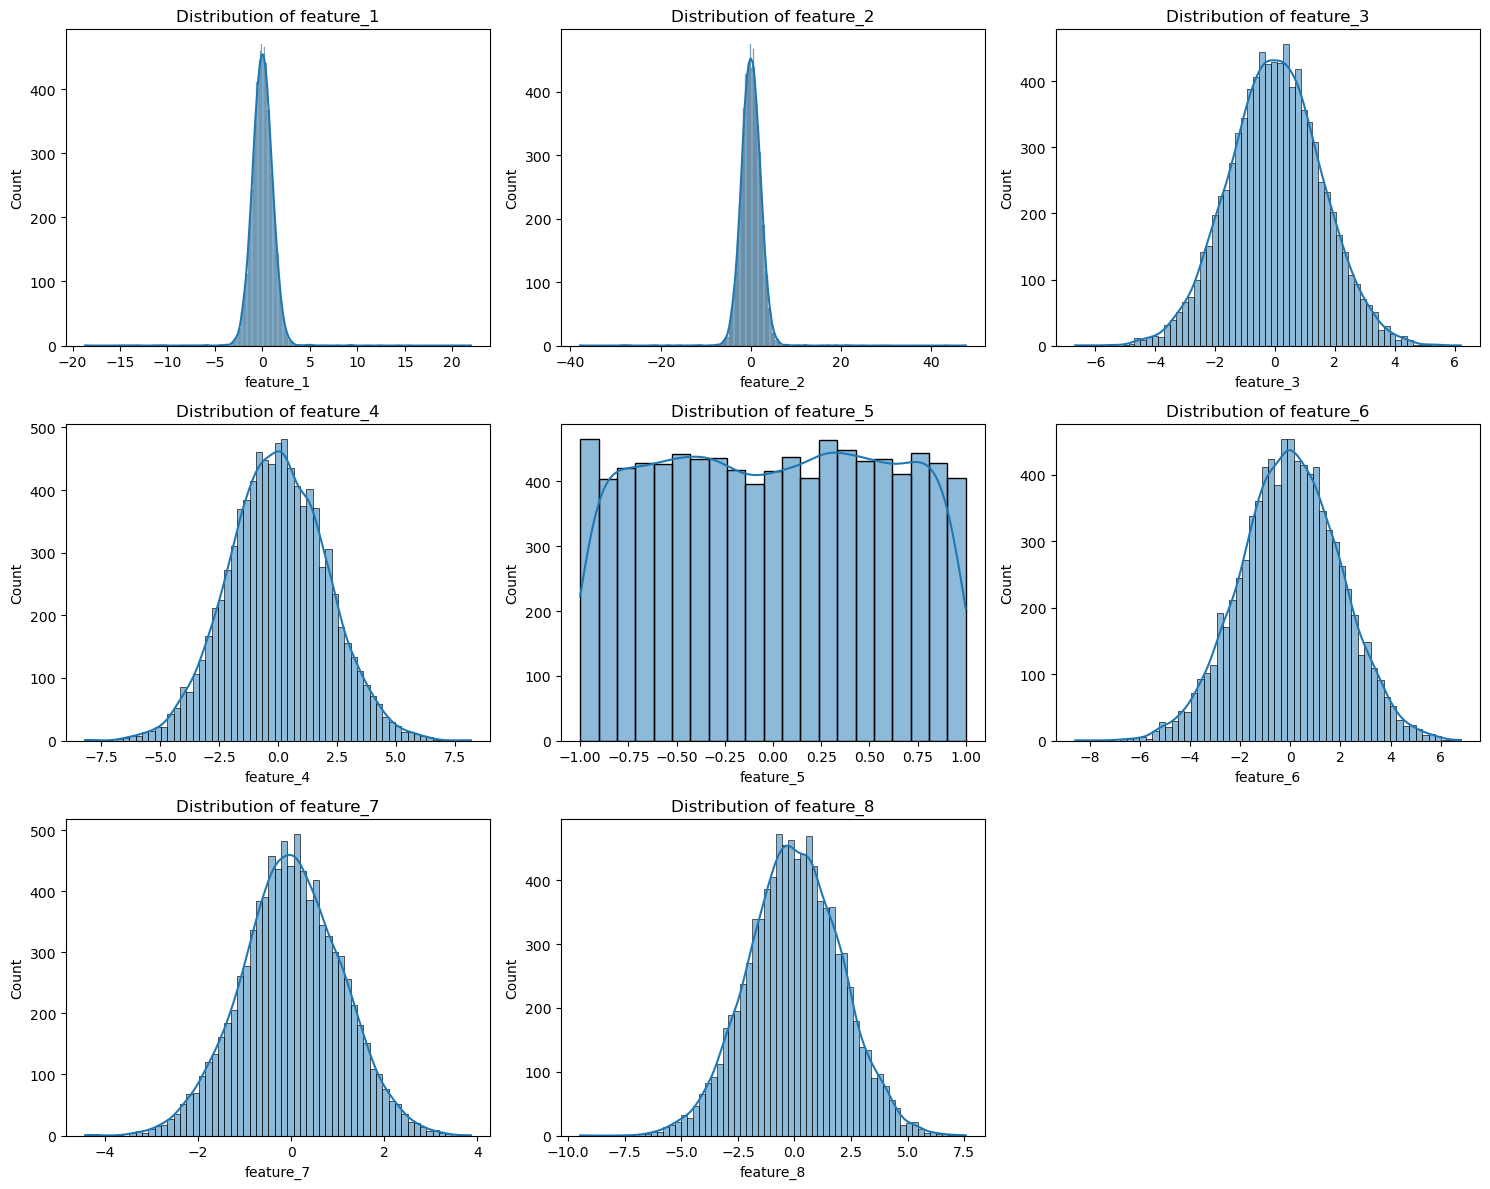

feature_1 → Skewness: 0.54, Kurtosis: 45.84
feature_2 → Skewness: 0.76, Kurtosis: 49.41
feature_3 → Skewness: -0.01, Kurtosis: 0.04
feature_4 → Skewness: 0.01, Kurtosis: 0.05
feature_5 → Skewness: -0.01, Kurtosis: -1.20
feature_6 → Skewness: -0.04, Kurtosis: -0.00
feature_7 → Skewness: -0.05, Kurtosis: 0.02
feature_8 → Skewness: -0.03, Kurtosis: 0.01


In [637]:
# Create a figure for numerical features
plt.figure(figsize=(15, 12))

# Get numerical features
numerical_features = df.select_dtypes(include=['float64', 'int64']).columns.tolist()
numerical_features = [col for col in numerical_features if col != 'target']  # Exclude target

# Plot histograms for numerical features
for i, feature in enumerate(numerical_features):
    plt.subplot(3, 3, i+1)
    sns.histplot(df[feature], kde=True)
    plt.title(f'Distribution of {feature}')
    plt.tight_layout()

plt.savefig('numerical_distributions.png')
plt.show()

# Check the skewness and kurtosis score for each of these distributions.
for col in ['feature_1', 'feature_2','feature_3','feature_4','feature_5', 'feature_6', 'feature_7', 'feature_8']:
    print(f"{col} → Skewness: {skew(df[col].dropna()):.2f}, Kurtosis: {kurtosis(df[col].dropna()):.2f}")


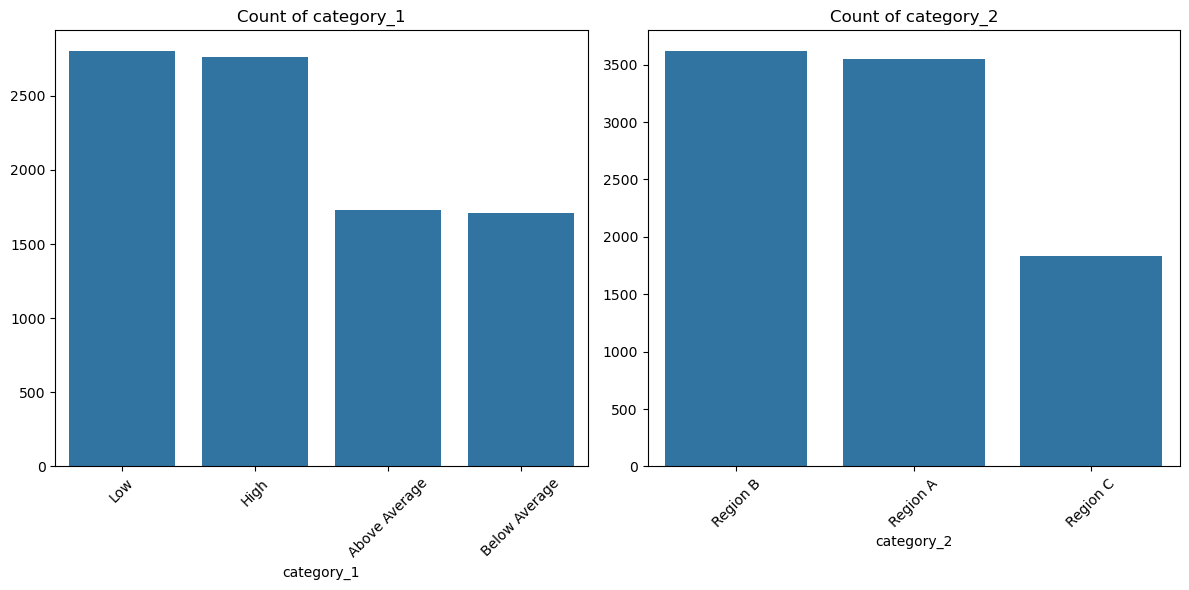

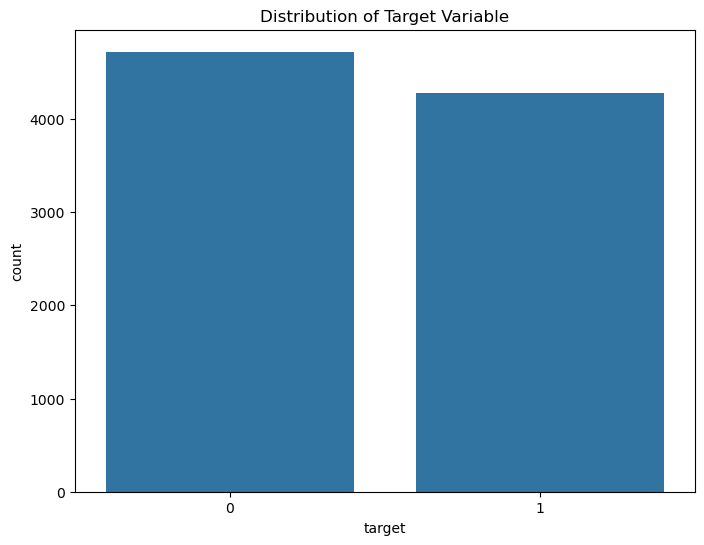

In [638]:
# Create the plot for categorical data
# Identify categorical features
categorical_features = df.select_dtypes(include=['object']).columns.tolist()

# Create bar plots for categorical features
plt.figure(figsize=(12, 6))
for i, feature in enumerate(categorical_features):
    plt.subplot(1, 2, i+1)
    value_counts = df[feature].value_counts()
    sns.barplot(x=value_counts.index, y=value_counts.values)
    plt.title(f'Count of {feature}')
    plt.xticks(rotation=45)
    plt.tight_layout()

plt.savefig('categorical_distributions.png')
plt.show()

# Examine target variable
plt.figure(figsize=(8, 6))
sns.countplot(x='target', data=df)
plt.title('Distribution of Target Variable')
plt.savefig('target_distribution.png')
plt.show()

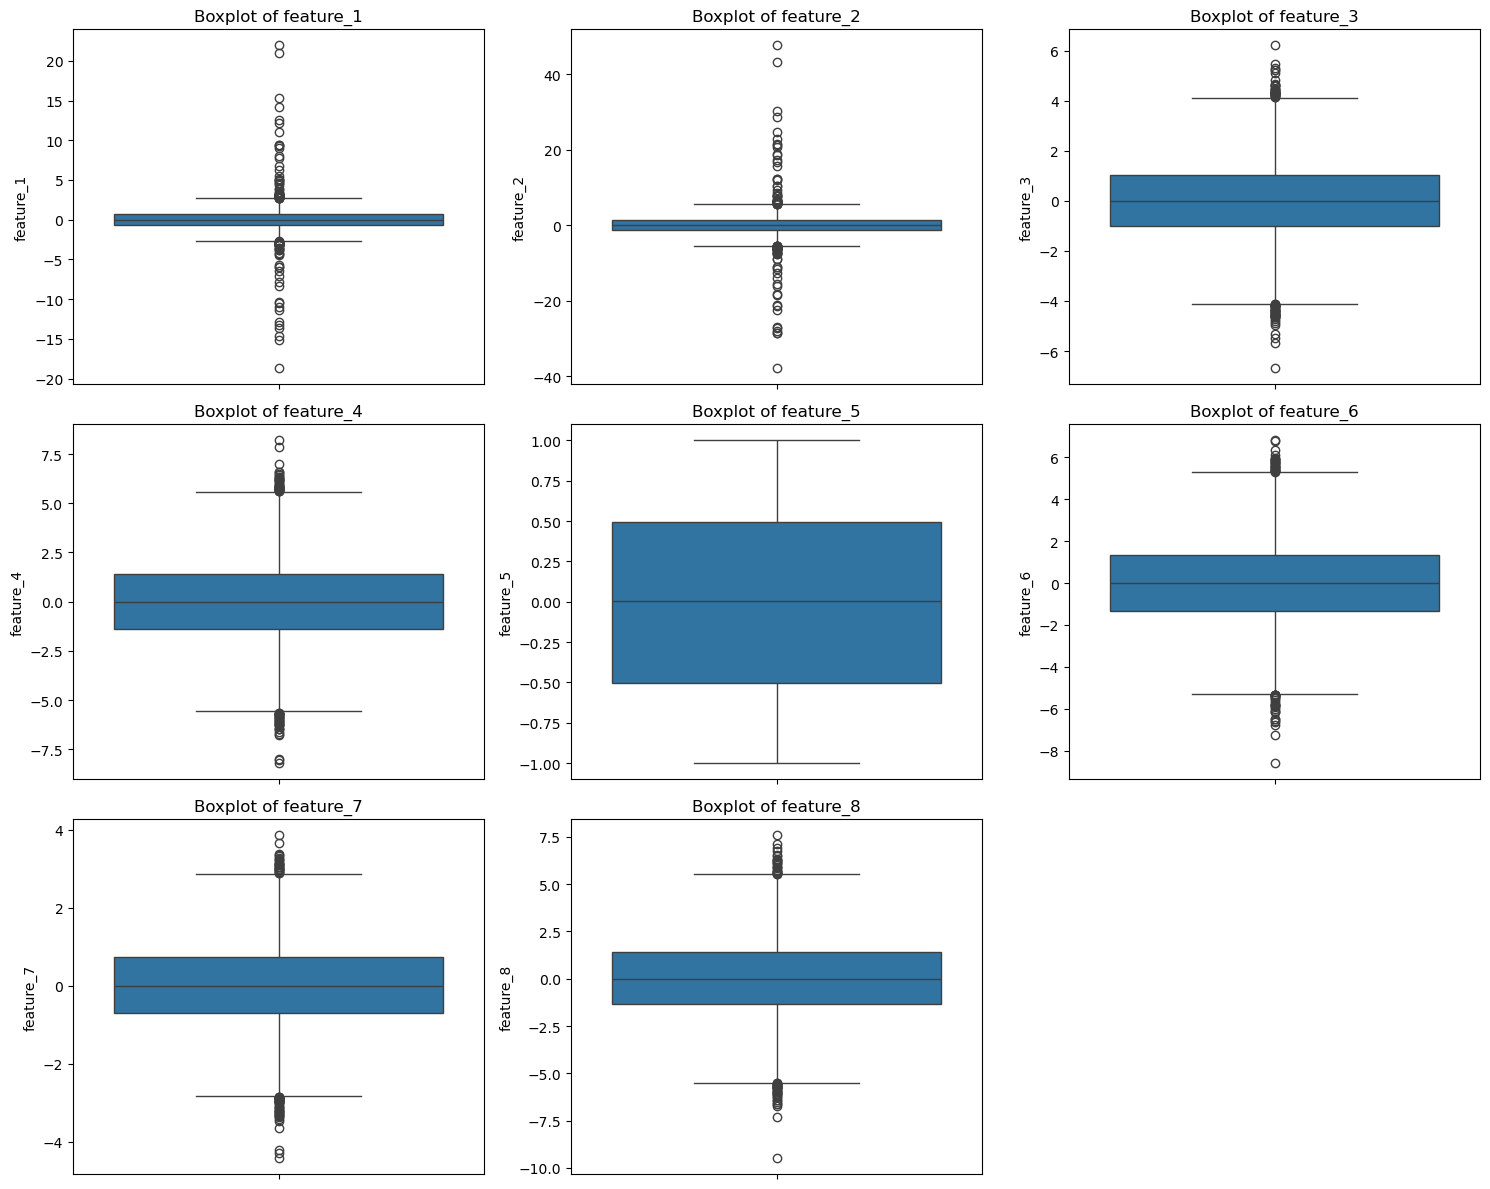

In [639]:
# Box plots to spot outliers
plt.figure(figsize=(15, 12))
for i, feature in enumerate(numerical_features):
    plt.subplot(3, 3, i+1)
    sns.boxplot(y=df[feature])
    plt.title(f'Boxplot of {feature}')
    plt.tight_layout()

plt.savefig('numerical_boxplots.png')
plt.show()

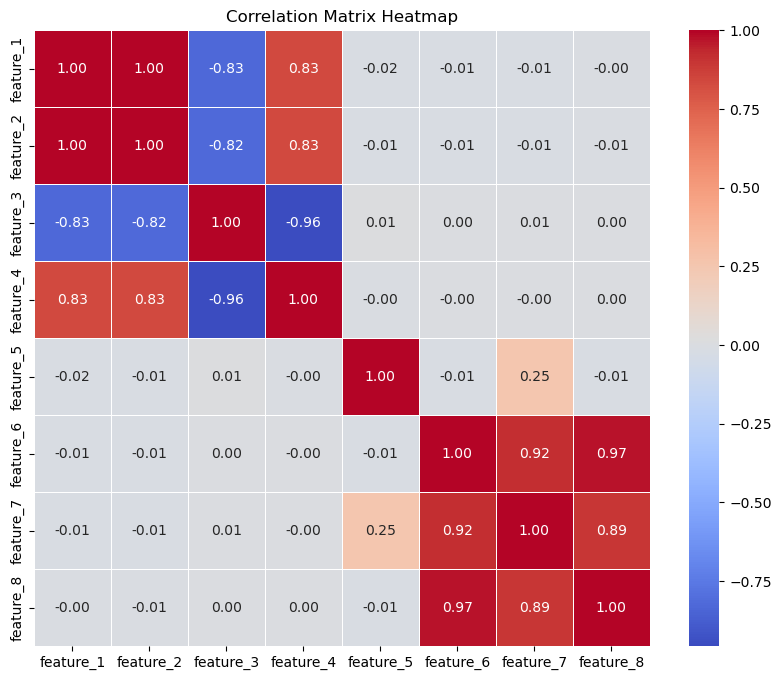

In [642]:
# Correlation matrix for numerical features
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', square=True, linewidths=0.5)
plt.title('Correlation Matrix Heatmap')
plt.savefig('Correlation Matrix Heatmap.png')
plt.show()

### 2. Data Preprocessing
Activity: Data Cleaning and Preparation

In [646]:
# Function to detect outliers using IQR
def detect_outliers_iqr(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)][column]
    return outliers, lower_bound, upper_bound


# Check for outliers in each numerical feature
outliers_summary = {}
for feature in numerical_features:
    outliers, lower_bound, upper_bound = detect_outliers_iqr(df, feature)
    outliers_percentage = (len(outliers) / len(df)) * 100
    outliers_summary[feature] = {
        "outliers_count": len(outliers),
        "percentage": outliers_percentage,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound
    }

# Display outliers summary
print("Outliers Summary:")
for feature, info in outliers_summary.items():
    print(f"{feature}: {info['outliers_count']} outliers ({info['percentage']:.2f}%)")
    print(f"   Lower bound: {info['lower_bound']:.2f}, Upper bound: {info['upper_bound']:.2f}")

Outliers Summary:
feature_1: 113 outliers (1.26%)
   Lower bound: -2.72, Upper bound: 2.72
feature_2: 106 outliers (1.18%)
   Lower bound: -5.53, Upper bound: 5.52
feature_3: 75 outliers (0.83%)
   Lower bound: -4.11, Upper bound: 4.13
feature_4: 71 outliers (0.79%)
   Lower bound: -5.59, Upper bound: 5.59
feature_5: 0 outliers (0.00%)
   Lower bound: -2.00, Upper bound: 2.00
feature_6: 59 outliers (0.66%)
   Lower bound: -5.31, Upper bound: 5.31
feature_7: 69 outliers (0.77%)
   Lower bound: -2.85, Upper bound: 2.88
feature_8: 61 outliers (0.68%)
   Lower bound: -5.49, Upper bound: 5.54


In [648]:
# Create a copy of the dataframe for preprocessing
df_imputed = df.copy()

# Separate numerical features into normal and skewed based on skewness
skewed_features = [f for f in numerical_features if abs(df[f].skew()) > 0.5]
normal_features = [f for f in numerical_features if abs(df[f].skew()) <= 0.5]

# Impute skewed features with median
median_imputer = SimpleImputer(strategy='median')
df_imputed[skewed_features] = median_imputer.fit_transform(df_imputed[skewed_features])

# Impute normal features with mean
mean_imputer = SimpleImputer(strategy='mean')
df_imputed[normal_features] = mean_imputer.fit_transform(df_imputed[normal_features])

# Check if any missing values remain
print("Missing values after imputation:")
print(df_imputed[numerical_features].isnull().sum())

# Handle outliers using clipping
# Creat a copy of the imputed dataset 
df_clean=df_imputed.copy()
for feature in numerical_features:
    lower_bound = outliers_summary[feature]['lower_bound']
    upper_bound = outliers_summary[feature]['upper_bound']
    
    # Clip values to be within bounds
    df_clean[feature] = df_clean[feature].clip(lower=lower_bound, upper=upper_bound)
    print(f"Clipped outliers in {feature} to range [{lower_bound:.2f}, {upper_bound:.2f}]")

# Verify no missing values remain
print("\nMissing values after imputation:")
print(df_clean.isnull().sum())

# Save the cleaned dataset
df_clean.to_csv('cleaned_dataset.csv', index=False)
df_encoded.to_csv('cleaned_encoded_dataset.csv', index=False)

Missing values after imputation:
feature_1    0
feature_2    0
feature_3    0
feature_4    0
feature_5    0
feature_6    0
feature_7    0
feature_8    0
dtype: int64
Clipped outliers in feature_1 to range [-2.72, 2.72]
Clipped outliers in feature_2 to range [-5.53, 5.52]
Clipped outliers in feature_3 to range [-4.11, 4.13]
Clipped outliers in feature_4 to range [-5.59, 5.59]
Clipped outliers in feature_5 to range [-2.00, 2.00]
Clipped outliers in feature_6 to range [-5.31, 5.31]
Clipped outliers in feature_7 to range [-2.85, 2.88]
Clipped outliers in feature_8 to range [-5.49, 5.54]

Missing values after imputation:
feature_1     0
feature_2     0
feature_3     0
feature_4     0
feature_5     0
feature_6     0
feature_7     0
feature_8     0
category_1    0
category_2    0
target        0
dtype: int64


In [650]:
# Scale the data because of using the models that are sensitive to scaling
scaler=StandardScaler()
df_clean[numerical_features] = scaler.fit_transform(df_clean[numerical_features])
df_clean.head()

,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,category_1,category_2,target
0,0.488558,0.559461,-0.435670,0.410834,1.363214,-1.150950,-1.218681,-1.105797,Above Average,Region C,1
1,-0.134837,-0.030220,-0.000251,0.201208,1.224232,-1.301954,-1.255315,-0.958141,Below Average,Region A,0
2,0.636778,0.680781,-0.512902,0.838285,-0.429268,1.024680,1.113257,0.738182,High,Region C,1
3,1.496152,1.296859,-1.646971,1.297736,1.531701,1.802542,1.984733,1.676208,High,Region B,1
4,-0.228977,-0.243744,0.382461,-0.211671,1.061302,0.113400,0.874965,-0.199620,Below Average,Region C,0


In [652]:
# Define the order explicitly
order = ['Low', 'Below Average', 'Above Average', 'High']
ordinal_encoder = OrdinalEncoder(categories=[order])
df_clean['category_1_encoded'] = ordinal_encoder.fit_transform(df[['category_1']])

# Drop the original category_1 column
df_clean.drop('category_1', axis=1, inplace=True)
df_clean.head()

,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,category_2,target,category_1_encoded
0,0.488558,0.559461,-0.435670,0.410834,1.363214,-1.150950,-1.218681,-1.105797,Region C,1,2.0
1,-0.134837,-0.030220,-0.000251,0.201208,1.224232,-1.301954,-1.255315,-0.958141,Region A,0,1.0
2,0.636778,0.680781,-0.512902,0.838285,-0.429268,1.024680,1.113257,0.738182,Region C,1,3.0
3,1.496152,1.296859,-1.646971,1.297736,1.531701,1.802542,1.984733,1.676208,Region B,1,3.0
4,-0.228977,-0.243744,0.382461,-0.211671,1.061302,0.113400,0.874965,-0.199620,Region C,0,1.0


In [654]:
# ----- One-Hot Encoding for category_2 -----
# Create and apply the encoder
onehot_encoder = OneHotEncoder(drop='first', sparse_output=False)  # drop='first' avoids dummy variable trap
category_2_encoded = onehot_encoder.fit_transform(df_clean[['category_2']])

# Create DataFrame for new one-hot columns
category_2_columns = onehot_encoder.get_feature_names_out(['category_2'])
category_2_df = pd.DataFrame(category_2_encoded, columns=category_2_columns, index=df_clean.index)

# Concatenate with df_clean
df_clean = pd.concat([df_clean, category_2_df], axis=1)

# Drop the original 'category_2' column
df_clean.drop('category_2', axis=1, inplace=True)

# ----- Final Output -----
print("Final DataFrame shape:", df_clean.shape)
print("Preview of processed data:")
print(df_clean.head())

Final DataFrame shape: (9000, 12)
Preview of processed data:
   feature_1  feature_2  feature_3  feature_4  feature_5  feature_6  \
0   0.488558   0.559461  -0.435670   0.410834   1.363214  -1.150950   
1  -0.134837  -0.030220  -0.000251   0.201208   1.224232  -1.301954   
2   0.636778   0.680781  -0.512902   0.838285  -0.429268   1.024680   
3   1.496152   1.296859  -1.646971   1.297736   1.531701   1.802542   
4  -0.228977  -0.243744   0.382461  -0.211671   1.061302   0.113400   

   feature_7  feature_8  target  category_1_encoded  category_2_Region B  \
0  -1.218681  -1.105797       1                 2.0                  0.0   
1  -1.255315  -0.958141       0                 1.0                  0.0   
2   1.113257   0.738182       1                 3.0                  0.0   
3   1.984733   1.676208       1                 3.0                  1.0   
4   0.874965  -0.199620       0                 1.0                  0.0   

   category_2_Region C  
0                  1.0  
1    

### 3. Exploratory Data Analysis (EDA)
Activity: In-depth EDA

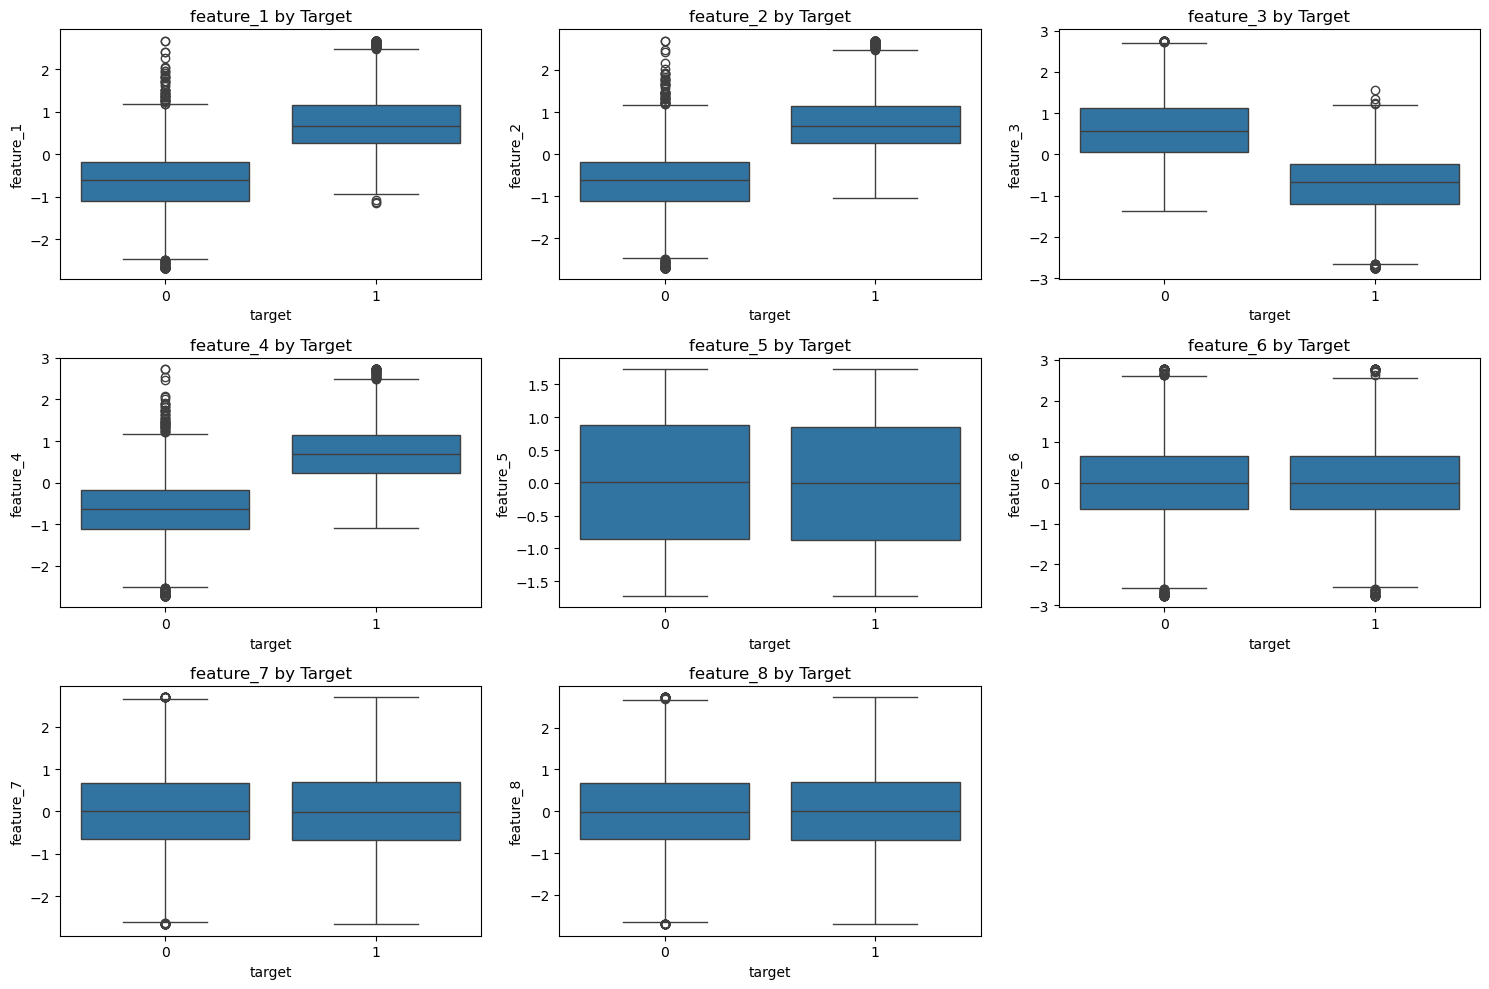

In [657]:
# Explore relationship between numerical features and target
plt.figure(figsize=(15, 10))
for i, feature in enumerate(numerical_features):
    plt.subplot(3, 3, i+1)
    sns.boxplot(x='target', y=feature, data=df_clean)
    plt.title(f'{feature} by Target')
    plt.tight_layout()
plt.savefig('numerical_by_target.png')
plt.show()

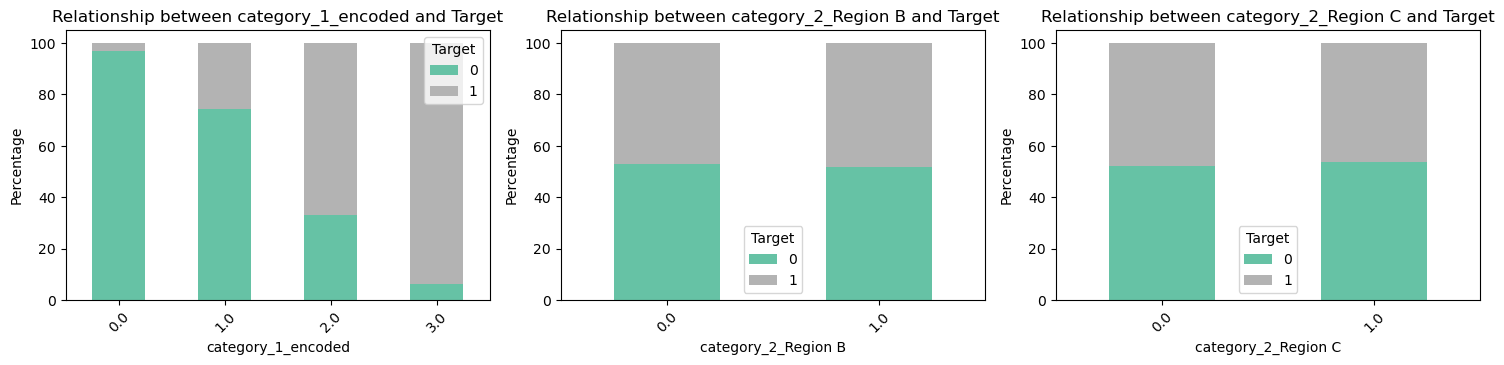

In [658]:
# Explore the relatinship between the categorical features and target
# Set up the plot
plt.figure(figsize=(15,10))

# Loop through each categorical feature
categorical_features = ['category_1_encoded', 'category_2_Region B', 'category_2_Region C']

for i, feature in enumerate(categorical_features):
    plt.subplot(3, 3, i + 1)

    # Create a crosstab to show counts of target per category
    ct = pd.crosstab(df_clean[feature], df_clean['target'])

    # Normalize to get percentages
    ct_pct = ct.div(ct.sum(axis=1), axis=0) * 100

    # Plot as stacked bar chart
    ct_pct.plot(kind='bar', stacked=True, ax=plt.gca(), colormap='Set2')

    plt.title(f'Relationship between {feature} and Target')
    plt.xlabel(feature)
    plt.ylabel('Percentage')
    plt.legend(title='Target')
    plt.xticks(rotation=45)
    plt.tight_layout()

# Save and show the figure
plt.savefig('categorical_features_vs_target.png')
plt.show()

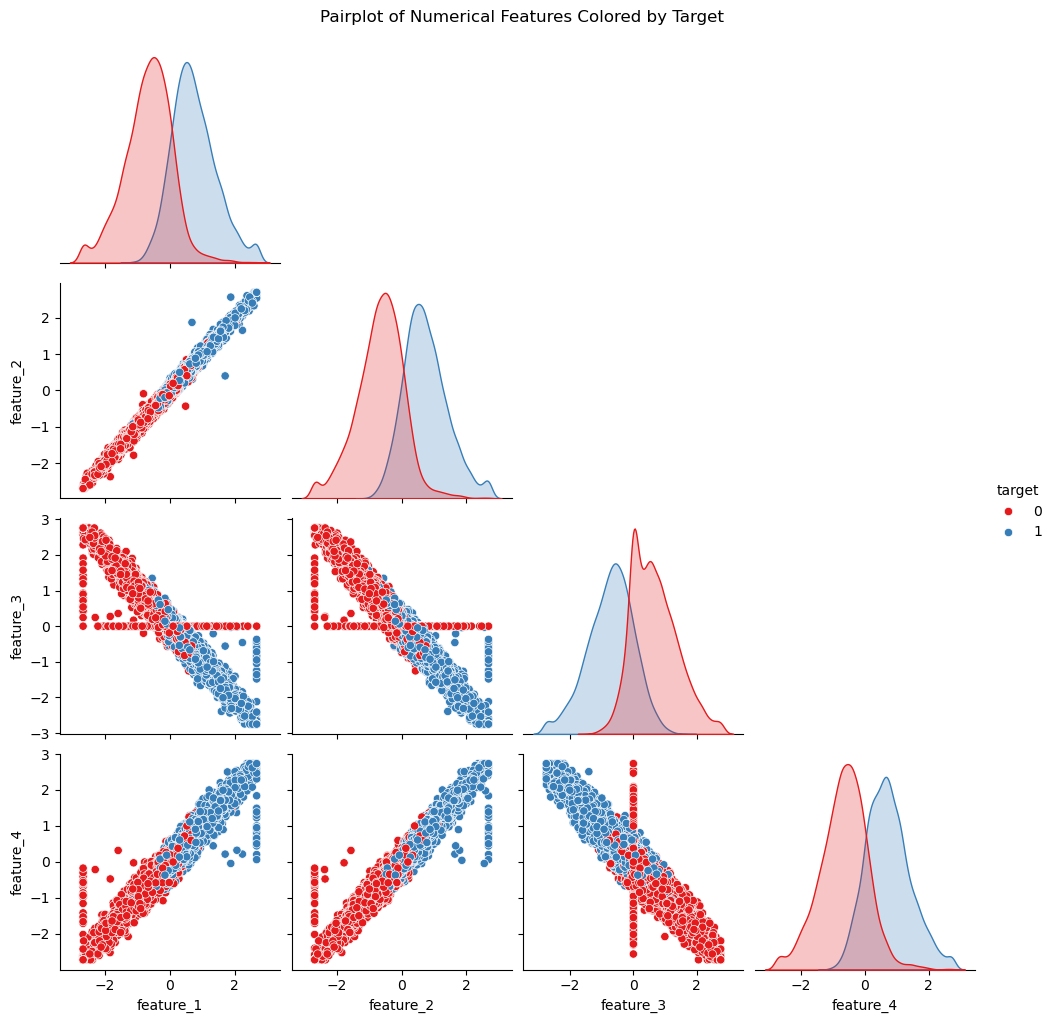

In [661]:
# Select numerical features to plot (excluding one-hot encoded categorical variables)
# Pairplot for key numerical features
# Select a subset of features if there are many

key_features = numerical_features[:4] + ['target']  # Adjust based on correlation analysis

# Create pairplot with target as hue
# hue:Color the data points based on the values in the 'target' column.
sns.pairplot(df_clean[key_features],hue='target', palette='Set1', diag_kind='kde', corner=True)
plt.suptitle('Pairplot of Numerical Features Colored by Target', y=1.02)
plt.savefig('pairplot.png')
plt.show()

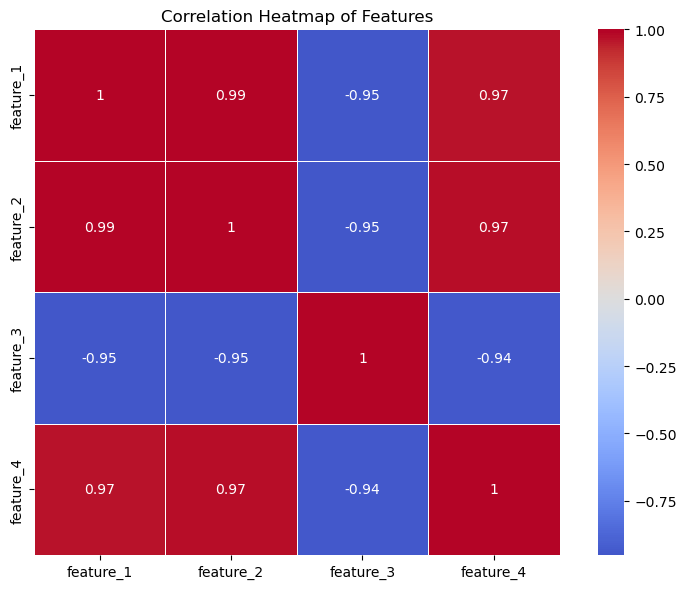

<Figure size 640x480 with 0 Axes>

In [767]:
# Check the corrolation between the features after Data processig
# Compute correlation matrix
corr = df_clean[['feature_1', 'feature_2', 'feature_3', 'feature_4']].corr()

# Plot the heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', center=0, square=True, linewidths=0.5)
plt.title('Correlation Heatmap of Features')
plt.tight_layout()
plt.show()
plt.savefig('correlation_heatmap.png')


In [663]:
# T-tests for numerical features by target
from scipy.stats import ttest_ind

# Let's loop over numerical features
for feature in numerical_features:
    group0 = df_clean[df_clean['target'] == 0][feature]
    group1 = df_clean[df_clean['target'] == 1][feature]
    
    t_stat, p_value = ttest_ind(group0, group1, equal_var=False)  # Welch’s t-test
    
    print(f"\nT-test for {feature}")
    print(f"t-statistic = {t_stat:.4f}, p-value = {p_value:.4f}")
    if p_value < 0.05:
        print("✅ Significant difference between target classes.")
    else:
        print("❌ No significant difference between target classes.")



T-test for feature_1
t-statistic = -94.4858, p-value = 0.0000
✅ Significant difference between target classes.

T-test for feature_2
t-statistic = -95.3020, p-value = 0.0000
✅ Significant difference between target classes.

T-test for feature_3
t-statistic = 90.8854, p-value = 0.0000
✅ Significant difference between target classes.

T-test for feature_4
t-statistic = -92.6618, p-value = 0.0000
✅ Significant difference between target classes.

T-test for feature_5
t-statistic = 0.7471, p-value = 0.4550
❌ No significant difference between target classes.

T-test for feature_6
t-statistic = -0.1632, p-value = 0.8704
❌ No significant difference between target classes.

T-test for feature_7
t-statistic = 0.1990, p-value = 0.8422
❌ No significant difference between target classes.

T-test for feature_8
t-statistic = -0.4722, p-value = 0.6368
❌ No significant difference between target classes.


In [664]:
# CHI-SQUARE TEST (for categorical features)
from scipy.stats import chi2_contingency

# Loop through categorical features (replace with your list)
for feature in categorical_features:
    contingency_table = pd.crosstab(df_clean[feature], df_clean['target'])
    chi2, p, dof, expected = chi2_contingency(contingency_table)

    print(f"\nChi-Square Test for {feature}")
    print(f"Chi2 Stat = {chi2:.4f}, p-value = {p:.4f}")
    if p < 0.05:
        print("✅ There is a relationship between this feature and target.")
    else:
        print("❌ No significant relationship.")



Chi-Square Test for category_1_encoded
Chi2 Stat = 5175.3203, p-value = 0.0000
✅ There is a relationship between this feature and target.

Chi-Square Test for category_2_Region B
Chi2 Stat = 0.7669, p-value = 0.3812
❌ No significant relationship.

Chi-Square Test for category_2_Region C
Chi2 Stat = 0.9965, p-value = 0.3182
❌ No significant relationship.


### 4. Feature Engineering
Activity: Create New Features

In [670]:
# 4. Feature Engineering
# Create a copy for feature engineering
df_featured = df_clean.copy()

# 1. Interaction terms between correlated numerical features
# Find highly correlated feature pairs
correlations = df_clean[numerical_features].corr().abs()
feature_pairs = []
for i in range(len(numerical_features)):
    for j in range(i+1, len(numerical_features)):
        if correlations.iloc[i, j] > 0.3:  # Threshold for correlation
            feature_pairs.append((numerical_features[i], numerical_features[j]))

print(f"Creating interaction terms for {len(feature_pairs)} feature pairs with correlation > 0.3")
for feat1, feat2 in feature_pairs:
    # Multiply features
    df_featured[f'{feat1}_x_{feat2}'] = df_featured[feat1] * df_featured[feat2]
    # Ratio (if makes sense for the domain)
    df_featured[f'{feat1}_div_{feat2}'] = df_featured[feat1] / (df_featured[feat2] + 1e-5)  # Avoid division by zero

# 2. Polynomial features for important numerical features
from sklearn.preprocessing import PolynomialFeatures

# Identify important features from correlation with target
target_correlations = df_clean[numerical_features + ['target']].corr()['target'].abs().sort_values(ascending=False)
important_features = target_correlations[target_correlations > 0.1].index.tolist()
important_features = [f for f in important_features if f != 'target']

print(f"\nCreating polynomial features for {len(important_features)} important features")
if important_features:
    poly = PolynomialFeatures(degree=2, include_bias=False, interaction_only=False)
    poly_features = poly.fit_transform(df_featured[important_features])
    poly_feature_names = [f"poly_{i}" for i in range(poly_features.shape[1])]
    
    # Add polynomial features to dataframe
    poly_df = pd.DataFrame(poly_features, columns=poly_feature_names)
    df_featured = pd.concat([df_featured, poly_df], axis=1)

# 4. Binning important continuous features
df_featured_binned= df_featured.copy()
for feature in numerical_features:
    # Create 4 bins
    df_featured_binned[f'{feature}_binned'] = pd.qcut(df_featured[feature], q=4, labels=False, duplicates='drop')

# Save the featured dataset
df_featured.to_csv('featured_dataset.csv', index=False)
df_featured_binned.to_csv('featured_dataset_binned.csv', index=False)
# Save the heatmap as an image
plt.savefig('correlation_heatmap.png')
plt.show()
# Report on new features
print("\nOriginal number of features:", len(df_clean.columns))
print("Number of features after feature engineering:", len(df_featured.columns))
print("New features created:", len(df_featured.columns) - len(df_clean.columns))


Creating interaction terms for 9 feature pairs with correlation > 0.3

Creating polynomial features for 4 important features

Original number of features: 12
Number of features after feature engineering: 44
New features created: 32


### 5. Modeling
Activity: Build and Evaluate Models

In [673]:
# 5. Modeling
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import StackingClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
import time



# Split data into features and target
X = df_featured_binned.drop('target', axis=1)
y = df_featured_binned['target']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

models = {
    'Logistic Regression': LogisticRegression(max_iter=10000),
    'K-Nearest Neighbors': KNeighborsClassifier(n_neighbors=5),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'SVM (RBF Kernel)': SVC(probability=True),
    # Ensemble models
    'Random Forest': RandomForestClassifier(n_estimators=100),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, random_state=42),
    'AdaBoost': AdaBoostClassifier(n_estimators=100, algorithm='SAMME',random_state=42), 
    'XGBoost': XGBClassifier(eval_metric='logloss'),
    'Stacking Classifier':StackingClassifier(
        estimators=[
        ('lr', LogisticRegression(random_state=42)),
        ('rf', RandomForestClassifier(random_state=42)),
        ('DT', DecisionTreeClassifier(random_state=42))
        ],
        final_estimator=LogisticRegression(random_state=42),
        cv=5 
)
}

# Function to evaluate model
def evaluate_model(model, X_train, X_test, y_train, y_test):
    # Train the model
    start_time = time.time()
    model.fit(X_train, y_train)
    training_time = time.time() - start_time
    
    # Make predictions
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1] if hasattr(model, "predict_proba") else None
    
    # Cross-validation
    cv_scores = cross_val_score(model, X_train, y_train, cv=5, scoring='accuracy')
    
    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_prob) if y_prob is not None else None
    
    return {
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'roc_auc': roc_auc,
        'cv_scores': cv_scores,
        'cv_mean': cv_scores.mean(),
        'cv_std': cv_scores.std(),
        'training_time': training_time,
        'model': model,
        'predictions': y_pred,
        'probabilities': y_prob
    }

results = {}
for name, model in models.items():
    print(f"\nTraining {name}...")
    results[name] = evaluate_model(model, X_train, X_test, y_train, y_test)
    print(f"  Accuracy: {results[name]['accuracy']:.4f}")
    print(f"  Precision: {results[name]['precision']:.4f}")
    print(f"  Recall: {results[name]['recall']:.4f}")
    print(f"  F1 Score: {results[name]['f1']:.4f}")
    if results[name]['roc_auc'] is not None:
        print(f"  ROC AUC: {results[name]['roc_auc']:.4f}")
    print(f"  CV Accuracy: {results[name]['cv_mean']:.4f} (±{results[name]['cv_std']:.4f})")
    print(f"  Training Time: {results[name]['training_time']:.2f} seconds")


# Compare models
model_names = list(results.keys())
metrics = ['accuracy', 'precision', 'recall', 'f1', 'cv_mean']
comparison = pd.DataFrame(index=model_names, columns=metrics)

for name in model_names:
    for metric in metrics:
        comparison.loc[name, metric] = results[name][metric]

print("\nModel Comparison:")
print(comparison)


Training set shape: (7200, 51)
Testing set shape: (1800, 51)

Training Logistic Regression...
  Accuracy: 0.8894
  Precision: 0.8953
  Recall: 0.8692
  F1 Score: 0.8820
  ROC AUC: 0.9597
  CV Accuracy: 0.8856 (±0.0088)
  Training Time: 3.59 seconds

Training K-Nearest Neighbors...
  Accuracy: 0.8628
  Precision: 0.8561
  Recall: 0.8551
  F1 Score: 0.8556
  ROC AUC: 0.9293
  CV Accuracy: 0.8529 (±0.0046)
  Training Time: 0.00 seconds

Training Decision Tree...
  Accuracy: 0.8428
  Precision: 0.8383
  Recall: 0.8294
  F1 Score: 0.8338
  ROC AUC: 0.8422
  CV Accuracy: 0.8325 (±0.0043)
  Training Time: 0.22 seconds

Training SVM (RBF Kernel)...
  Accuracy: 0.5244
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
  ROC AUC: 0.9557
  CV Accuracy: 0.5246 (±0.0003)
  Training Time: 7.74 seconds

Training Random Forest...
  Accuracy: 0.8878
  Precision: 0.8968
  Recall: 0.8633
  F1 Score: 0.8798
  ROC AUC: 0.9593
  CV Accuracy: 0.8785 (±0.0075)
  Training Time: 1.58 seconds

Training Grad

<Figure size 500x300 with 0 Axes>

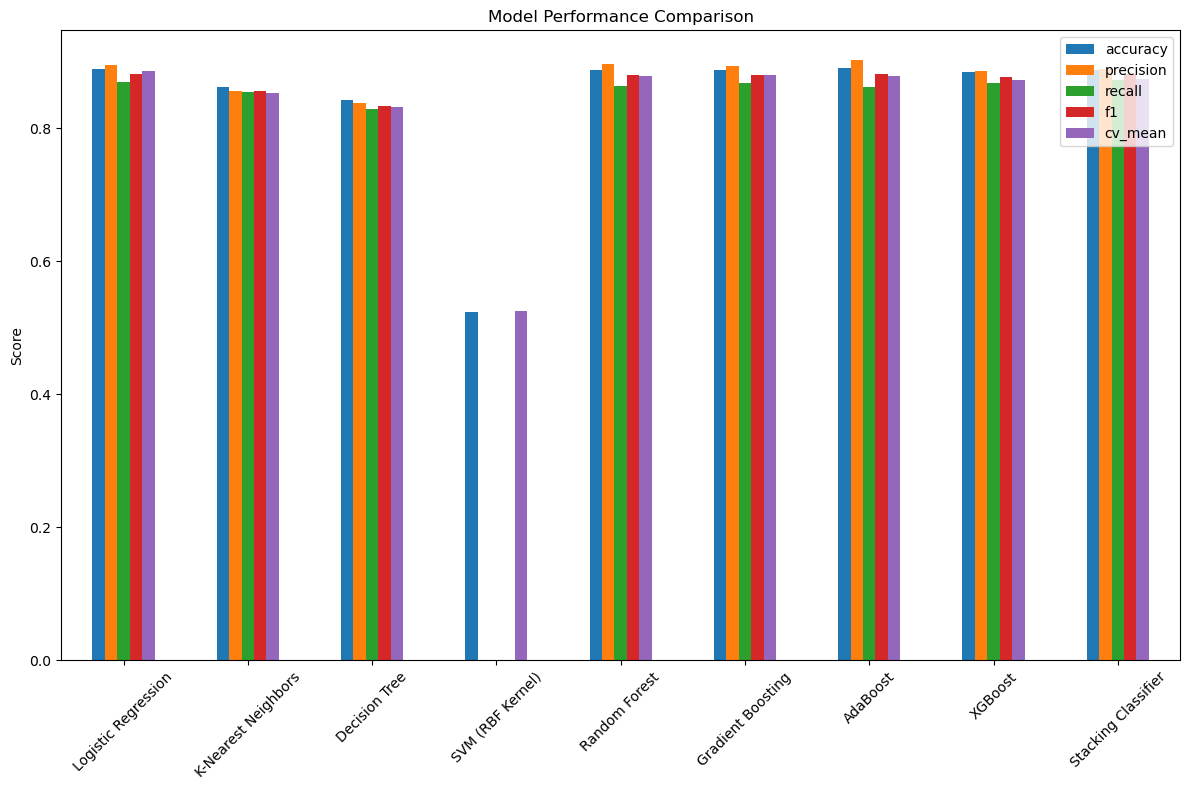

In [683]:
# Visualize results
plt.figure(figsize=(5, 3))
comparison.plot(kind='bar', figsize=(12, 8))
plt.title('Model Performance Comparison')
plt.ylabel('Score')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('model_comparison.png')
plt.show()

In [679]:
# Save all trained models from the results dictionary to disk as .pkl files using joblib,
# naming each file based on the model's name in lowercase with underscores.
# This allows for easy reuse of models without retraining.
# Save best models
import joblib
for name, result in results.items():
    joblib.dump(result['model'], f'{name.replace(" ", "_").lower()}_model.pkl')
    print(f"Saved {name} model to {name.replace(' ', '_').lower()}_model.pkl")

Saved Logistic Regression model to logistic_regression_model.pkl
Saved K-Nearest Neighbors model to k-nearest_neighbors_model.pkl
Saved Decision Tree model to decision_tree_model.pkl
Saved SVM (RBF Kernel) model to svm_(rbf_kernel)_model.pkl
Saved Random Forest model to random_forest_model.pkl
Saved Gradient Boosting model to gradient_boosting_model.pkl
Saved AdaBoost model to adaboost_model.pkl
Saved XGBoost model to xgboost_model.pkl
Saved Stacking Classifier model to stacking_classifier_model.pkl


### 6. Model Tuning
Activity: Hyperparameter Tuning

In [694]:
# 6. Hyperparameter Tuning

from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

# Dictionary to store tuned models
tuned_models = {}

# 1. Define hyperparameter grids for selected models
param_grids = {
    'Logistic Regression': {
        'C': [ 0.1, 1, 10],
        'solver': ['liblinear']
    },
    'Random Forest': {
        'n_estimators': [100, 200],
        'max_depth': [None, 10, 20],
        'min_samples_split': [2, 5]
    },
    'Gradient Boosting': {
        'n_estimators': [100, 200],
        'learning_rate': [0.05, 0.1, 0.2],
        'max_depth': [3, 5]
    },
    'XGBoost': {
        'n_estimators': [100, 200],
        'learning_rate': [0.05, 0.1],
        'max_depth': [3, 5],
        'subsample': [0.8, 1]
    },
    'AdaBoost': {
        'n_estimators': [50,100,200],
        'learning_rate': [0.01,0.1, 1.0],
        'algorithm': ['SAMME']
    }
}

# 2. Base model instances for tuning
base_models = {
    'Logistic Regression': LogisticRegression(max_iter=10000),
    'Random Forest': RandomForestClassifier(random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'XGBoost': XGBClassifier(eval_metric='logloss'),
    'AdaBoost': AdaBoostClassifier(random_state=42)
}

# 3. Grid Search for each model
for name, model in base_models.items():
    print(f"\nTuning {name}...")
    grid = GridSearchCV(
        estimator=model,
        param_grid=param_grids[name],
        scoring='accuracy',           # You could also try 'f1' or 'roc_auc'
        cv=5,
        n_jobs=-1,                    # Use all processors
        verbose=1
    )
    grid.fit(X_train, y_train)

    # Store the best model
    tuned_models[name] = grid.best_estimator_

    print(f"  Best Parameters for {name}: {grid.best_params_}")
    print(f"  Best CV Accuracy: {grid.best_score_:.4f}")



Tuning Logistic Regression...
Fitting 5 folds for each of 3 candidates, totalling 15 fits
  Best Parameters for Logistic Regression: {'C': 0.1, 'solver': 'liblinear'}
  Best CV Accuracy: 0.8856

Tuning Random Forest...
Fitting 5 folds for each of 12 candidates, totalling 60 fits
  Best Parameters for Random Forest: {'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 200}
  Best CV Accuracy: 0.8806

Tuning Gradient Boosting...
Fitting 5 folds for each of 12 candidates, totalling 60 fits
  Best Parameters for Gradient Boosting: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100}
  Best CV Accuracy: 0.8828

Tuning XGBoost...
Fitting 5 folds for each of 16 candidates, totalling 80 fits
  Best Parameters for XGBoost: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100, 'subsample': 1}
  Best CV Accuracy: 0.8828

Tuning AdaBoost...
Fitting 5 folds for each of 9 candidates, totalling 45 fits
  Best Parameters for AdaBoost: {'algorithm': 'SAMME', 'learning_rate': 1.0, '

In [698]:
# Evaluate tuned models on the test set
tuned_results = {}
for name, model in tuned_models.items():
    print(f"\nEvaluating tuned {name}...")
    tuned_results[name] = evaluate_model(model, X_train, X_test, y_train, y_test)
    print(f"  Accuracy: {tuned_results[name]['accuracy']:.4f}")
    print(f"  Precision: {tuned_results[name]['precision']:.4f}")
    print(f"  Recall: {tuned_results[name]['recall']:.4f}")
    print(f"  F1 Score: {tuned_results[name]['f1']:.4f}")
    if tuned_results[name]['roc_auc'] is not None:
        print(f"  ROC AUC: {tuned_results[name]['roc_auc']:.4f}")
    #print(f"  CV Accuracy: {tuned_results[name]['cv_mean']:.4f} (±{tuned_results[name]['cv_std']:.4f})")



Evaluating tuned Logistic Regression...
  Accuracy: 0.8917
  Precision: 0.8930
  Recall: 0.8773
  F1 Score: 0.8851
  ROC AUC: 0.9593

Evaluating tuned Random Forest...
  Accuracy: 0.8883
  Precision: 0.9009
  Recall: 0.8598
  F1 Score: 0.8799
  ROC AUC: 0.9612

Evaluating tuned Gradient Boosting...
  Accuracy: 0.8928
  Precision: 0.9008
  Recall: 0.8703
  F1 Score: 0.8853
  ROC AUC: 0.9616

Evaluating tuned XGBoost...
  Accuracy: 0.8894
  Precision: 0.9001
  Recall: 0.8633
  F1 Score: 0.8813
  ROC AUC: 0.9617

Evaluating tuned AdaBoost...
  Accuracy: 0.8900
  Precision: 0.9022
  Recall: 0.8621
  F1 Score: 0.8817
  ROC AUC: 0.9596


In [702]:
# Step 5: Compare default vs tuned models

# Prepare list of rows
comparison_rows = []

# Default models
for name in results:
    comparison_rows.append({
        'Model': name,
        'Version': 'Default',
        'Accuracy': results[name]['accuracy'],
        'Precision': results[name]['precision'],
        'Recall': results[name]['recall'],
        'F1': results[name]['f1'],
        'CV_Mean': results[name].get('cv_mean', None)  # Use .get in case it's missing
    })

# Tuned models
for name in tuned_results:
    comparison_rows.append({
        'Model': name,
        'Version': 'Tuned',
        'Accuracy': tuned_results[name]['accuracy'],
        'Precision': tuned_results[name]['precision'],
        'Recall': tuned_results[name]['recall'],
        'F1': tuned_results[name]['f1'],
        'CV_Mean': tuned_results[name].get('cv_mean', None)
    })

# Convert to DataFrame
compare_df = pd.DataFrame(comparison_rows)

# Display comparison
print("\nComparison of Default vs. Tuned Models:")
print(compare_df.sort_values(by=['Model', 'Version']))



Comparison of Default vs. Tuned Models:
                  Model  Version  Accuracy  Precision    Recall        F1  \
6              AdaBoost  Default  0.890000   0.902200  0.862150  0.881720   
13             AdaBoost    Tuned  0.890000   0.902200  0.862150  0.881720   
2         Decision Tree  Default  0.842778   0.838253  0.829439  0.833823   
5     Gradient Boosting  Default  0.887778   0.893029  0.867991  0.880332   
11    Gradient Boosting    Tuned  0.892778   0.900846  0.870327  0.885324   
1   K-Nearest Neighbors  Default  0.862778   0.856140  0.855140  0.855640   
0   Logistic Regression  Default  0.889444   0.895307  0.869159  0.882039   
9   Logistic Regression    Tuned  0.891667   0.892985  0.877336  0.885091   
4         Random Forest  Default  0.887778   0.896845  0.863318  0.879762   
10        Random Forest    Tuned  0.888333   0.900857  0.859813  0.879857   
3      SVM (RBF Kernel)  Default  0.524444   0.000000  0.000000  0.000000   
8   Stacking Classifier  Default  0

In [704]:
# List of metrics you want to evaluate improvement on
metrics = ['Accuracy', 'Precision', 'Recall', 'F1']

# Dictionary to store improvement DataFrames
improvement_tables = {}

for metric in metrics:
    # Filter Default and Tuned rows
    default_df = compare_df[compare_df['Version'] == 'Default'].set_index('Model')
    tuned_df = compare_df[compare_df['Version'] == 'Tuned'].set_index('Model')
    
    # Ensure only common models are compared
    common_models = default_df.index.intersection(tuned_df.index)

    # Create improvement DataFrame
    improvement_df = pd.DataFrame({
        f'original_{metric.lower()}': default_df.loc[common_models][metric],
        f'tuned_{metric.lower()}': tuned_df.loc[common_models][metric],
    })

    # Calculate percentage improvement
    improvement_df['improvement'] = (
        (improvement_df[f'tuned_{metric.lower()}'] - improvement_df[f'original_{metric.lower()}']) /
        improvement_df[f'original_{metric.lower()}'] * 100
    ).round(2).astype(str) + '%'

    improvement_tables[metric] = improvement_df

    # Display it
    print(f"\nTuning Improvement ({metric}):")
    print(improvement_df)




Tuning Improvement (Accuracy):
                     original_accuracy  tuned_accuracy improvement
Model                                                             
Logistic Regression           0.889444        0.891667       0.25%
Random Forest                 0.887778        0.888333       0.06%
Gradient Boosting             0.887778        0.892778       0.56%
AdaBoost                      0.890000        0.890000        0.0%
XGBoost                       0.884444        0.889444       0.57%

Tuning Improvement (Precision):
                     original_precision  tuned_precision improvement
Model                                                               
Logistic Regression            0.895307         0.892985      -0.26%
Random Forest                  0.896845         0.900857       0.45%
Gradient Boosting              0.893029         0.900846       0.88%
AdaBoost                       0.902200         0.902200        0.0%
XGBoost                        0.886635         0.90

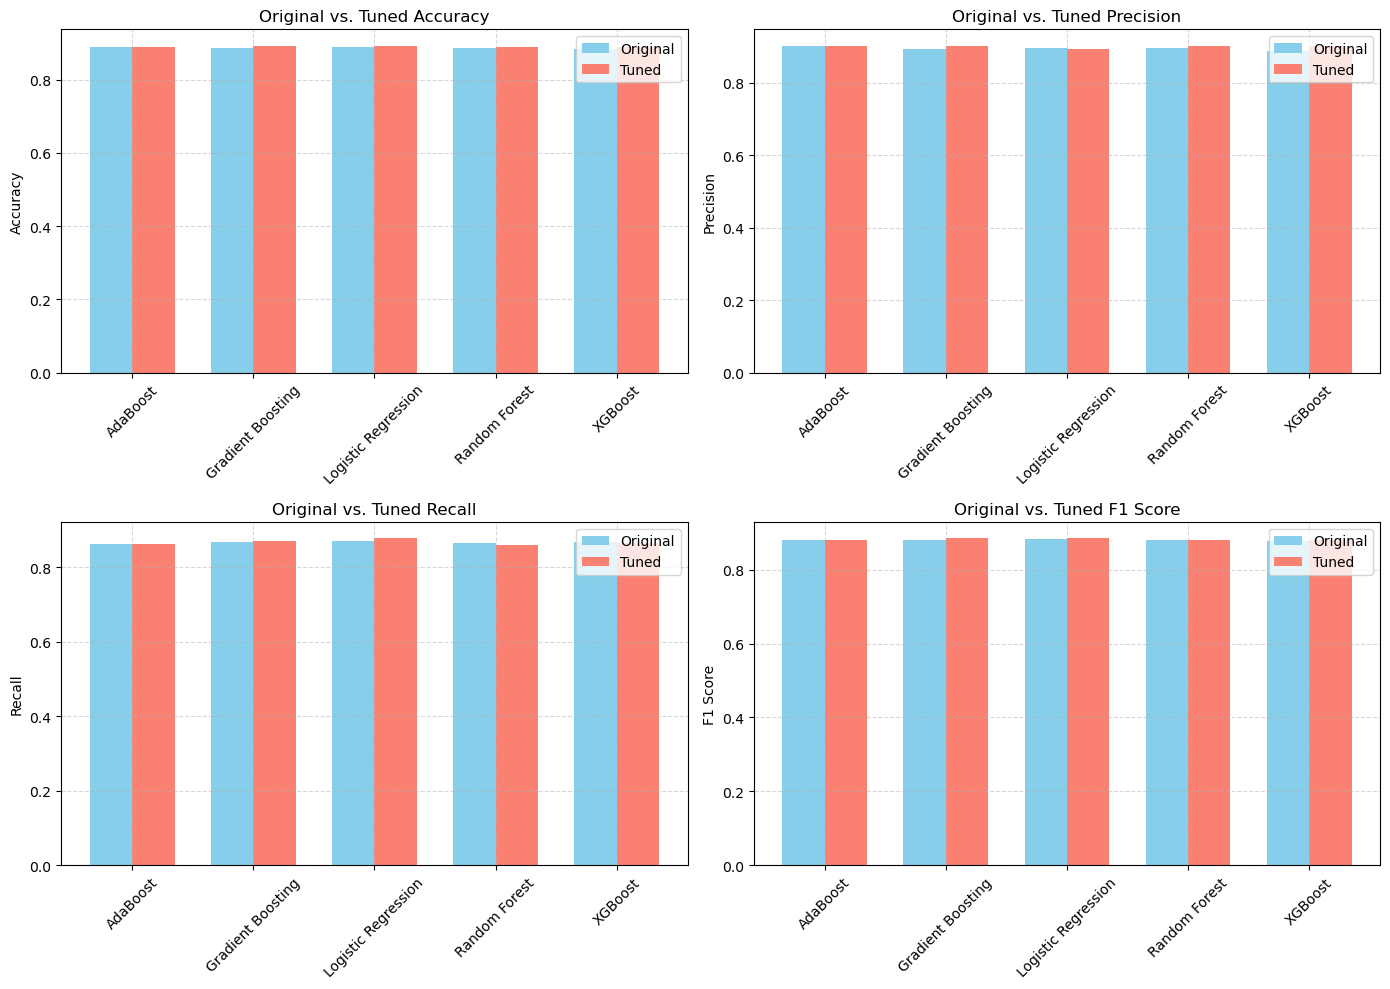

In [710]:
# List of models (ensure it matches your tuned and original results)

# Get only models that exist in both results and tuned_results
models = sorted(set(results.keys()).intersection(tuned_results.keys()))
x = np.arange(len(models))
width = 0.35

# Metrics to visualize
metrics = ['accuracy', 'precision', 'recall', 'f1']
metric_labels = ['Accuracy', 'Precision', 'Recall', 'F1 Score']

# Create subplots for each metric
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, metric in enumerate(metrics):
    original_values = [results[model][metric] for model in models]
    tuned_values = [tuned_results[model][metric] for model in models]

    ax = axes[i]
    ax.bar(x - width/2, original_values, width, label='Original', color='skyblue')
    ax.bar(x + width/2, tuned_values, width, label='Tuned', color='salmon')
    ax.set_title(f'Original vs. Tuned {metric_labels[i]}')
    ax.set_xticks(x)
    ax.set_xticklabels(models, rotation=45)
    ax.set_ylabel(metric_labels[i])
    ax.legend()
    ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('model_tuning_comparison_all_metrics.png')
plt.show()


In [712]:
# step 6: save and tune the model
# Save best tuned models
import joblib
for name, model in tuned_models.items():
    filename = f'tuned_{name.replace(" ", "_").lower()}_model.pkl'
    joblib.dump(model, filename)
    print(f"Saved {name} tuned model to {filename}")


Saved Logistic Regression tuned model to tuned_logistic_regression_model.pkl
Saved Random Forest tuned model to tuned_random_forest_model.pkl
Saved Gradient Boosting tuned model to tuned_gradient_boosting_model.pkl
Saved XGBoost tuned model to tuned_xgboost_model.pkl
Saved AdaBoost tuned model to tuned_adaboost_model.pkl


### 7. Model Interpretation
Activity: Interpret the Model

In [725]:
# Find the best model based on F1 score
best_model_name = max(tuned_results.items(), key=lambda x: x[1]['f1'])[0]
best_model = tuned_results[best_model_name]['model']
print(f"Best model: {best_model_name}")

Best model: Gradient Boosting


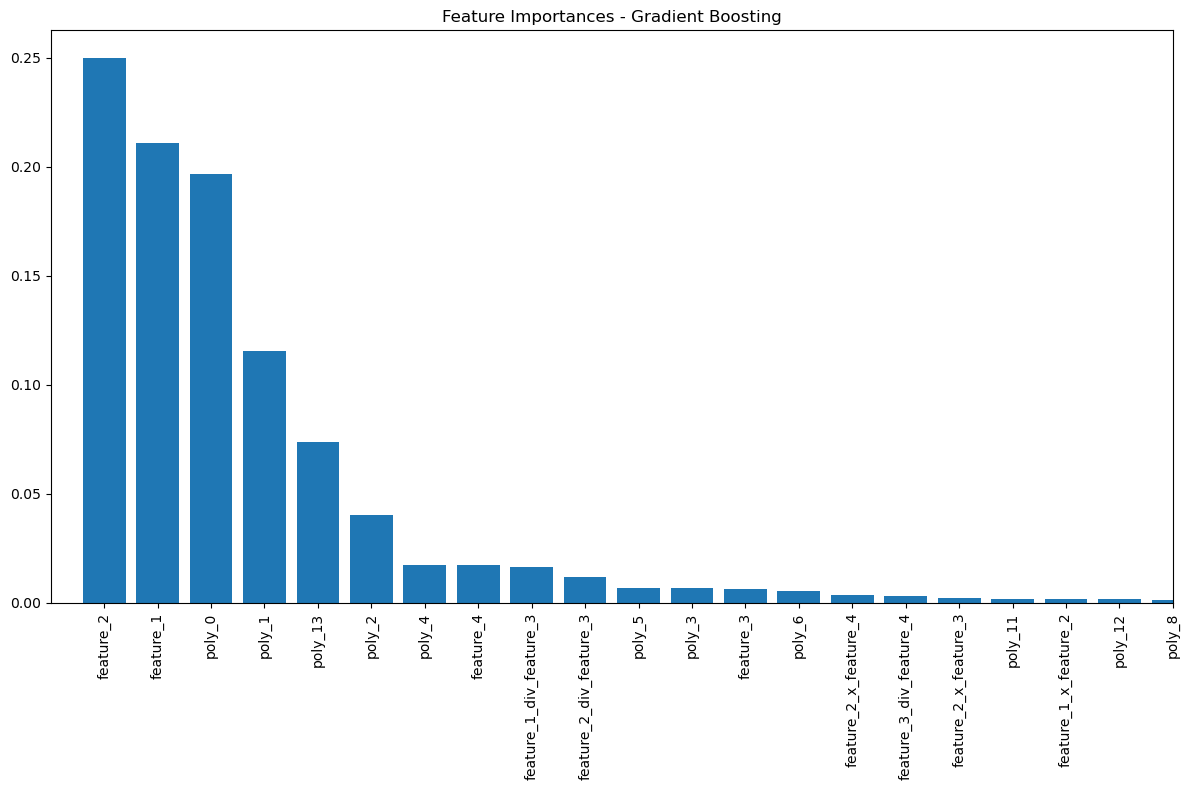


Top 10 Most Important Features:
1. feature_2 - 0.2502
2. feature_1 - 0.2108
3. poly_0 - 0.1969
4. poly_1 - 0.1154
5. poly_13 - 0.0737
6. poly_2 - 0.0402
7. poly_4 - 0.0172
8. feature_4 - 0.0171
9. feature_1_div_feature_3 - 0.0165
10. feature_2_div_feature_3 - 0.0119


In [727]:
# Extract feature importances (if available)
if hasattr(best_model, 'feature_importances_'):
    importances = best_model.feature_importances_
    indices = np.argsort(importances)[::-1]
    
    # Plot feature importances
    plt.figure(figsize=(12, 8))
    plt.title(f'Feature Importances - {best_model_name}')
    plt.bar(range(X.shape[1]), importances[indices], align='center')
    plt.xticks(range(X.shape[1]), X.columns[indices], rotation=90)
    plt.xlim([-1, min(20, X.shape[1])])  # Show top 20 features at most
    plt.tight_layout()
    plt.savefig('feature_importances.png')
    plt.show()
    
    # Print top 10 features
    print("\nTop 10 Most Important Features:")
    for i in range(min(10, X.shape[1])):
        print(f"{i+1}. {X.columns[indices[i]]} - {importances[indices[i]]:.4f}")



=== Logistic Regression ===


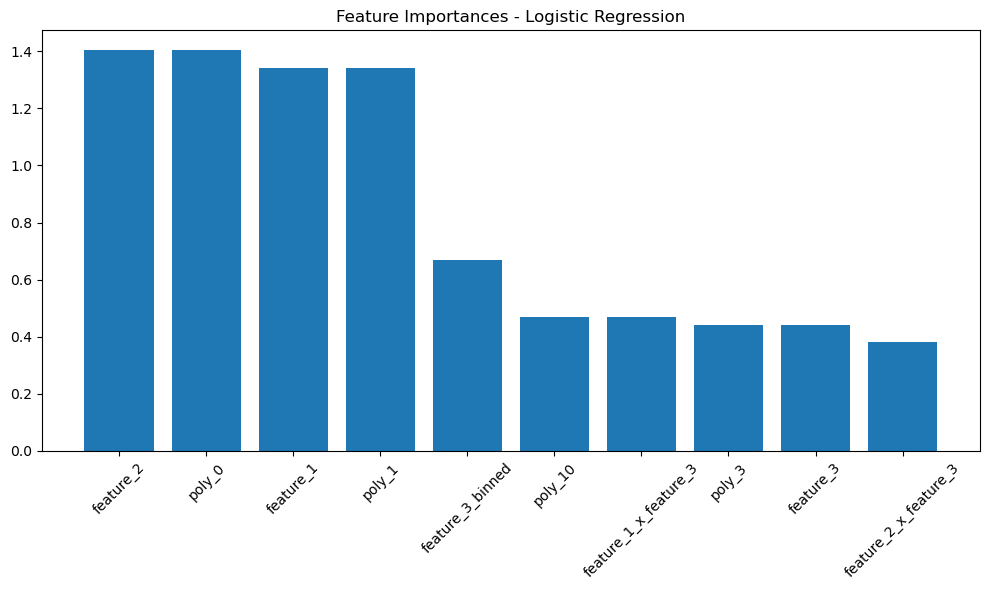

Top 10 features:
1. feature_2 - 1.4032
2. poly_0 - 1.4032
3. feature_1 - 1.3423
4. poly_1 - 1.3423
5. feature_3_binned - 0.6691
6. poly_10 - 0.4697
7. feature_1_x_feature_3 - 0.4697
8. poly_3 - 0.4395
9. feature_3 - 0.4395
10. feature_2_x_feature_3 - 0.3828
Error loading or processing Decision Tree: [Errno 2] No such file or directory: 'tuned_decision_tree_model.pkl'

=== Random Forest ===


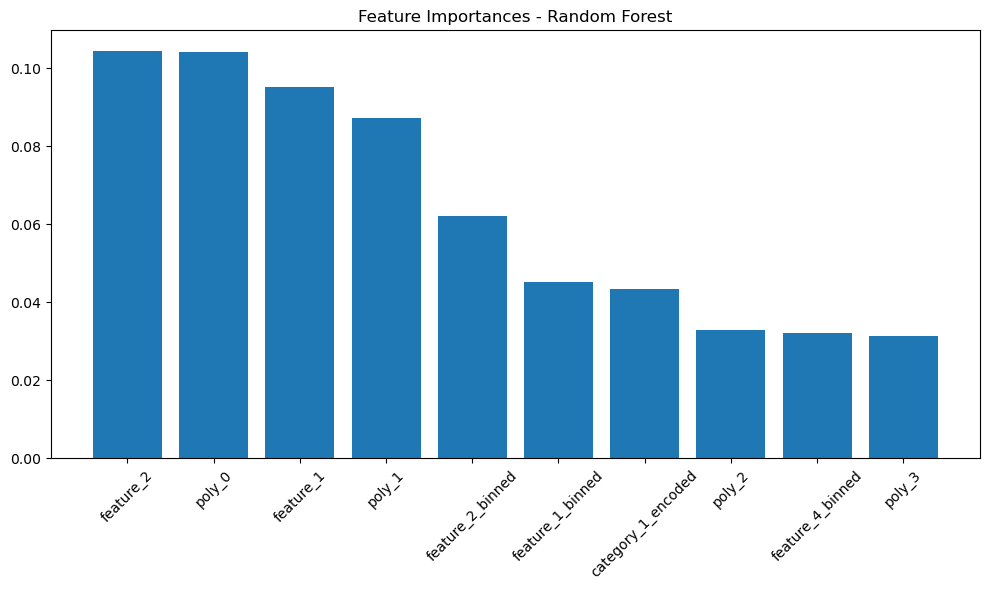

Top 10 features:
1. feature_2 - 0.1046
2. poly_0 - 0.1042
3. feature_1 - 0.0954
4. poly_1 - 0.0874
5. feature_2_binned - 0.0621
6. feature_1_binned - 0.0452
7. category_1_encoded - 0.0434
8. poly_2 - 0.0330
9. feature_4_binned - 0.0322
10. poly_3 - 0.0314

=== Gradient Boosting ===


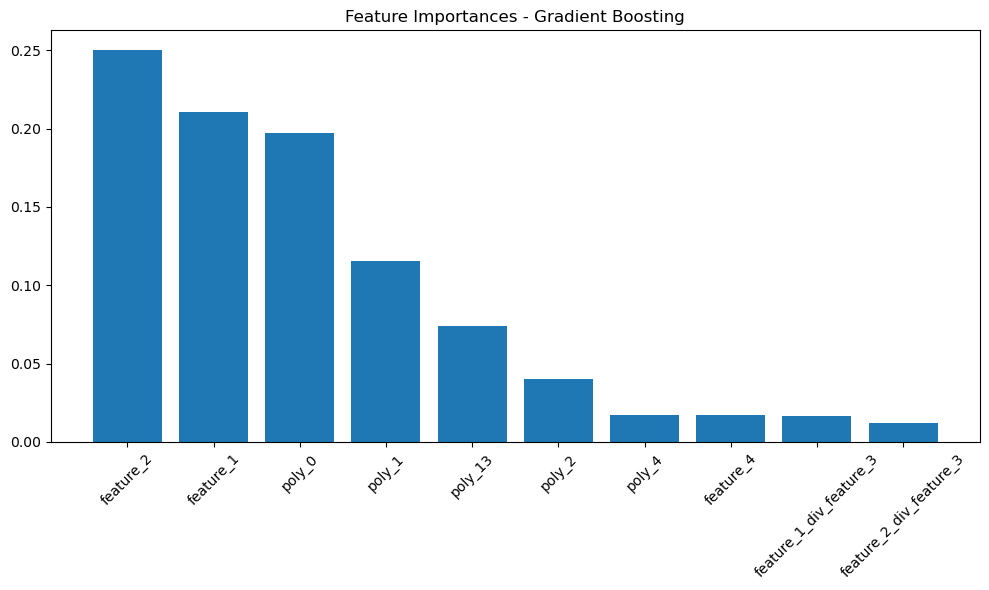

Top 10 features:
1. feature_2 - 0.2502
2. feature_1 - 0.2108
3. poly_0 - 0.1969
4. poly_1 - 0.1154
5. poly_13 - 0.0737
6. poly_2 - 0.0402
7. poly_4 - 0.0172
8. feature_4 - 0.0171
9. feature_1_div_feature_3 - 0.0165
10. feature_2_div_feature_3 - 0.0119

=== XGBoost ===


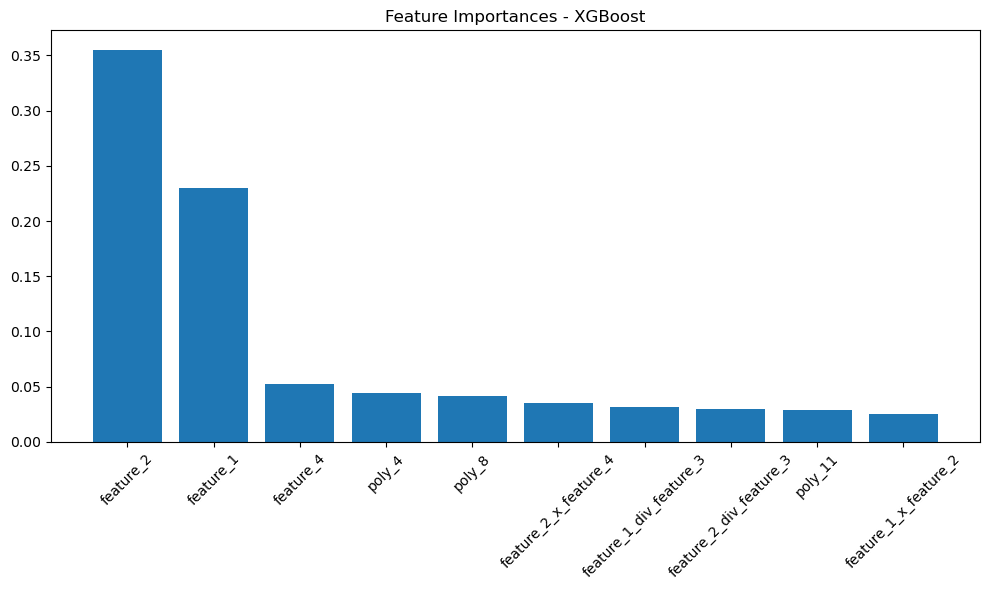

Top 10 features:
1. feature_2 - 0.3550
2. feature_1 - 0.2299
3. feature_4 - 0.0526
4. poly_4 - 0.0441
5. poly_8 - 0.0418
6. feature_2_x_feature_4 - 0.0352
7. feature_1_div_feature_3 - 0.0312
8. feature_2_div_feature_3 - 0.0301
9. poly_11 - 0.0292
10. feature_1_x_feature_2 - 0.0256

=== AdaBoost ===


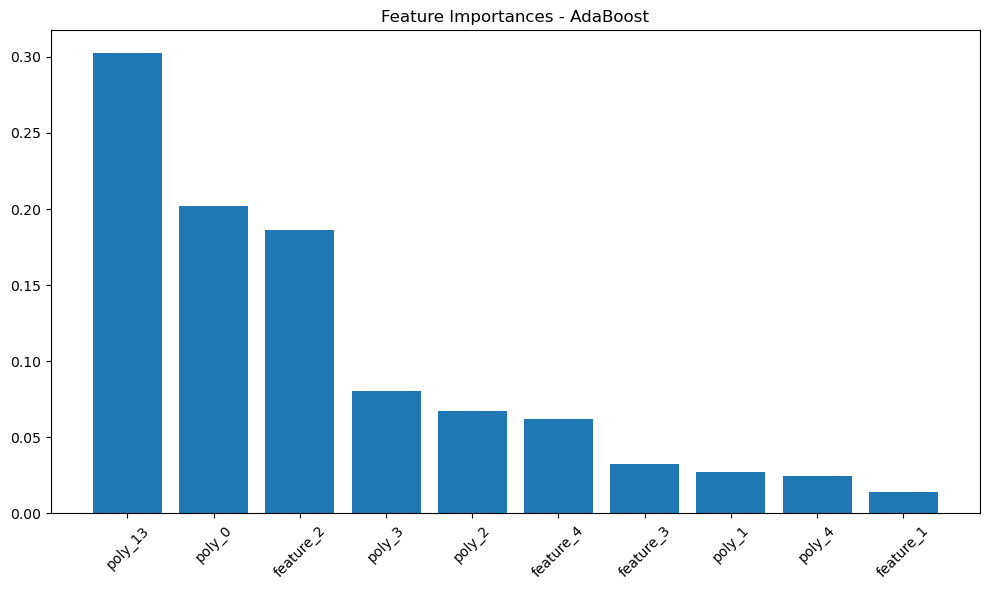

Top 10 features:
1. poly_13 - 0.3023
2. poly_0 - 0.2023
3. feature_2 - 0.1859
4. poly_3 - 0.0802
5. poly_2 - 0.0676
6. feature_4 - 0.0619
7. feature_3 - 0.0325
8. poly_1 - 0.0273
9. poly_4 - 0.0247
10. feature_1 - 0.0142


In [731]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import os

# Load your models
model_paths = {
    'Logistic Regression': 'tuned_logistic_regression_model.pkl',
    'Random Forest': 'tuned_random_forest_model.pkl',
    'Gradient Boosting': 'tuned_gradient_boosting_model.pkl',
    'XGBoost': 'tuned_xgboost_model.pkl',
    'AdaBoost': 'tuned_adaboost_model.pkl',
}


# Make sure your feature names are accessible
# X should be your feature dataframe
feature_names = X.columns

# Directory to save plots
os.makedirs("feature_importance_plots", exist_ok=True)

# Loop through models
for model_name, file_path in model_paths.items():
    try:
        model = joblib.load(file_path)
        print(f"\n=== {model_name} ===")
        
        if hasattr(model, 'feature_importances_'):
            # Tree-based models
            importances = model.feature_importances_
        
        elif hasattr(model, 'coef_'):
            # Linear models like Logistic Regression
            importances = np.abs(model.coef_).flatten()  # Use absolute value for magnitude
            
        else:
            print(f"{model_name} does not support direct feature importances.")
            continue
        
        # Sort importances
        indices = np.argsort(importances)[::-1]
        
        # Plot
        plt.figure(figsize=(10, 6))
        plt.title(f'Feature Importances - {model_name}')
        plt.bar(range(min(10, len(importances))), importances[indices[:10]], align='center')
        plt.xticks(range(min(10, len(importances))), [feature_names[i] for i in indices[:10]], rotation=45)
        plt.tight_layout()
        plot_filename = f"feature_importance_plots/{model_name.replace(' ', '_').lower()}_importance.png"
        plt.savefig(plot_filename)
        plt.show()
        
        # Print top 10
        print("Top 10 features:")
        for i in range(min(10, len(importances))):
            print(f"{i+1}. {feature_names[indices[i]]} - {importances[indices[i]]:.4f}")
    
    except Exception as e:
        print(f"Error loading or processing {model_name}: {e}")



Computing SHAP values...
✅ SHAP values computed successfully.


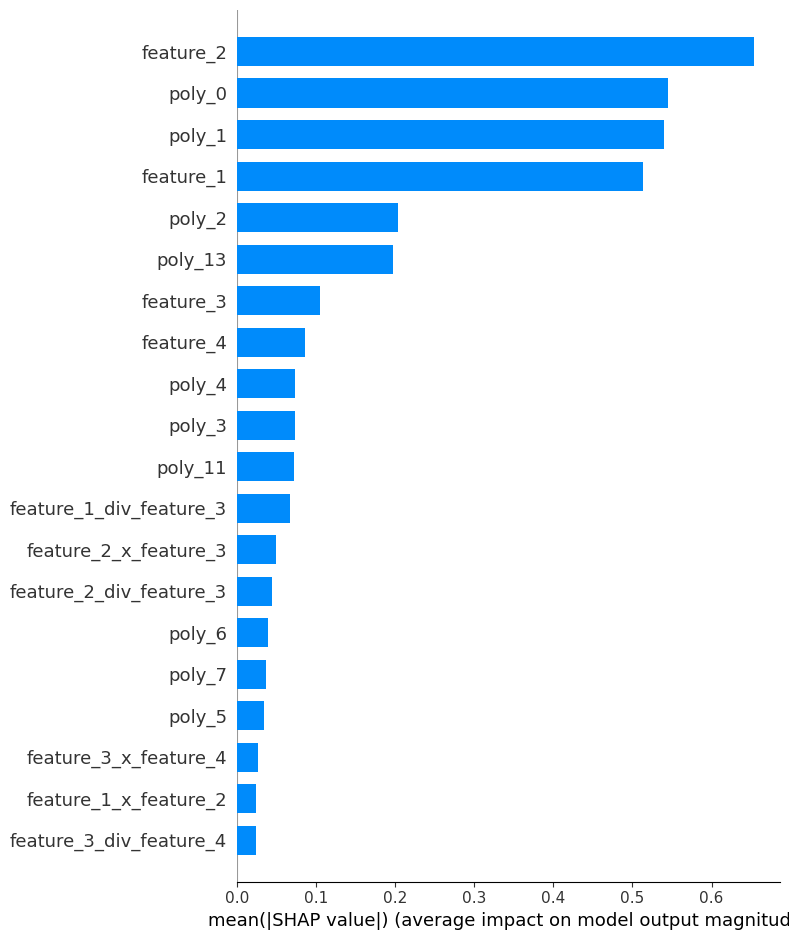

<Figure size 1000x600 with 0 Axes>

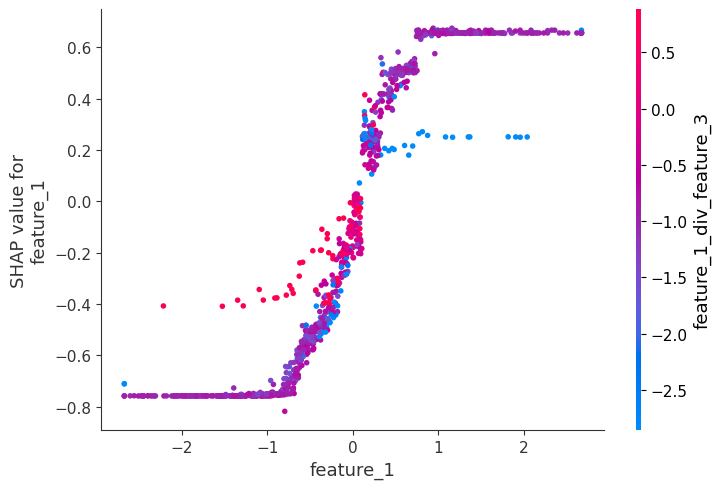

<Figure size 1000x600 with 0 Axes>

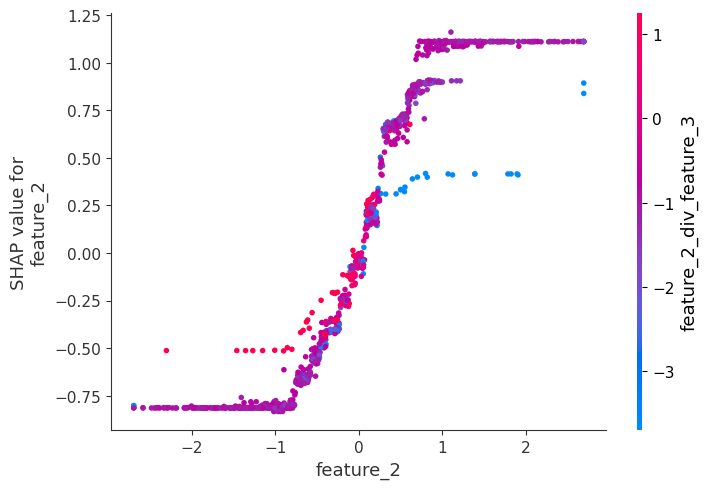

<Figure size 1000x600 with 0 Axes>

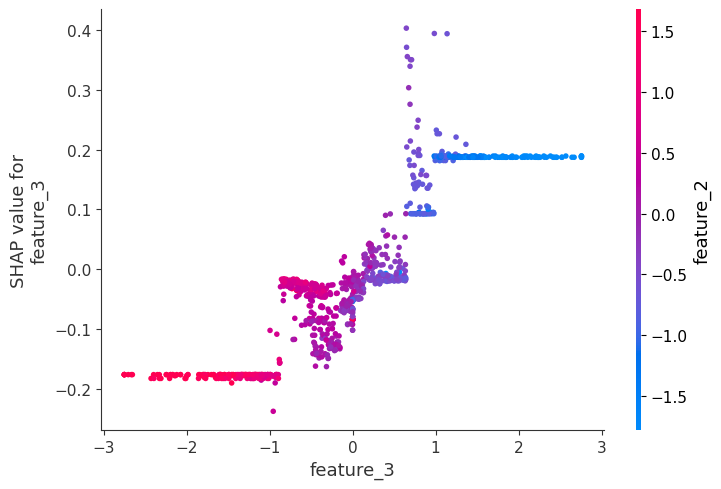

<Figure size 1000x600 with 0 Axes>

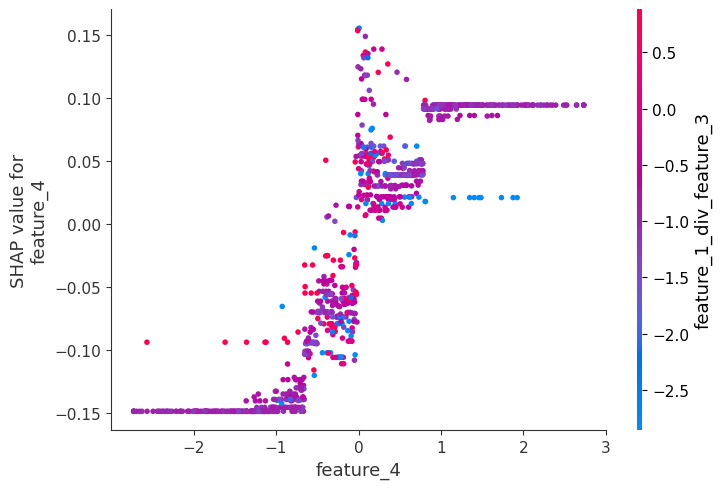

<Figure size 1000x600 with 0 Axes>

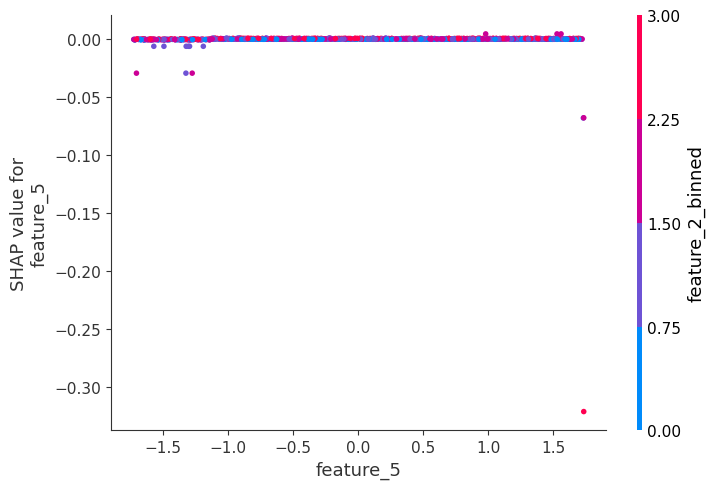

In [747]:
# SHAP analysis for the best model
# Note: This may be computationally intensive, adjust sample size if needed
try:
    print("\nComputing SHAP values...")
    # Use a sample of the test set if it's large
    X_sample = X_test.sample(min(1000, len(X_test)), random_state=42)

    if best_model_name == 'Random Forest':
        explainer = shap.TreeExplainer(best_model)
        shap_values = explainer.shap_values(X_sample)
        print("✅ SHAP values computed successfully.")  # Feedback added

        # Summary plot
        plt.figure(figsize=(12, 10))
        shap.summary_plot(shap_values[1] if isinstance(shap_values, list) else shap_values, 
                          X_sample, plot_type="bar", show=False)
        plt.tight_layout()
        plt.savefig('shap_summary.png')
        plt.show()

        # Detailed SHAP values for individual features
        for feature in X.columns[:5]:  # Top 5 features
            plt.figure(figsize=(10, 6))
            shap.dependence_plot(feature, shap_values[1] if isinstance(shap_values, list) else shap_values, 
                                 X_sample, show=False)
            plt.tight_layout()
            plt.savefig(f'shap_dependence_{feature}.png')
            plt.show()

    elif best_model_name in ['Gradient Boosting', 'AdaBoost']:
        explainer = shap.TreeExplainer(best_model)
        shap_values = explainer.shap_values(X_sample)
        print("✅ SHAP values computed successfully.")  

        # Summary plot
        plt.figure(figsize=(12, 10))
        shap.summary_plot(shap_values, X_sample, plot_type="bar", show=False)
        plt.tight_layout()
        plt.savefig('shap_summary.png')
        plt.show()

        # Detailed SHAP values for individual features
        for feature in X.columns[:5]:  # Top 5 features
            plt.figure(figsize=(10, 6))
            shap.dependence_plot(feature, shap_values, X_sample, show=False)
            plt.tight_layout()
            plt.savefig(f'shap_dependence_{feature}.png')
            plt.show()

    else:
        print(f"SHAP analysis not implemented for {best_model_name}")

except Exception as e:
    print(f"Error in SHAP analysis: {e}")
    print("Continuing with other analyses...")


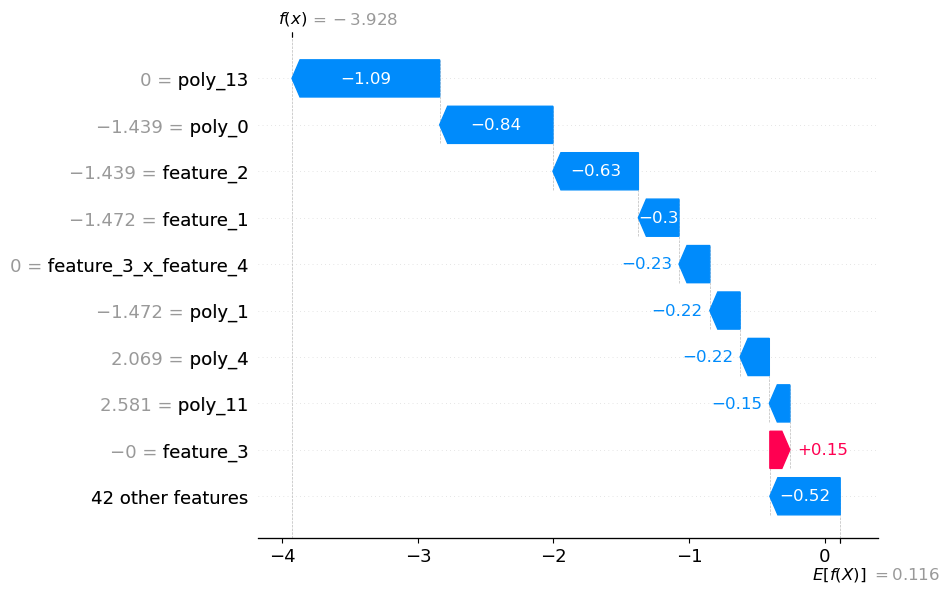

In [751]:
import shap

# Pick a sample to explain (index 0 by default)
sample_idx = 0
X_sample_row = X_test.iloc[[sample_idx]]

# Create TreeExplainer (optimized for tree-based models like GradientBoosting)
explainer = shap.Explainer(best_model, X_train)

# Compute SHAP values for the sample
shap_values = explainer(X_sample_row)

# Generate waterfall plot
shap.plots.waterfall(shap_values[0])


<Figure size 800x600 with 0 Axes>

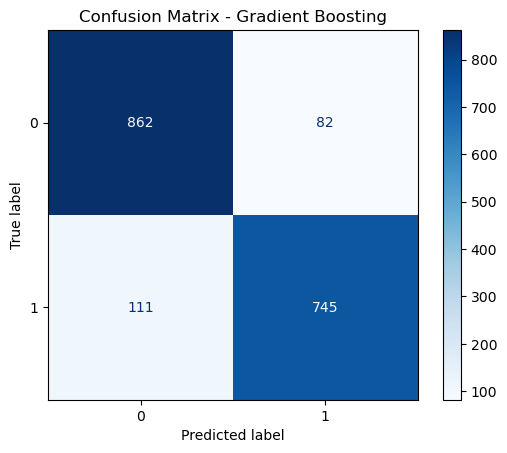

In [771]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Predict on test set
y_pred = best_model.predict(X_test)

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=best_model.classes_)

# Plot the confusion matrix
plt.figure(figsize=(8, 6))
disp.plot(cmap='Blues', values_format='d')
plt.title(f"Confusion Matrix - {best_model_name}")
plt.savefig("confusion_matrix.png")
plt.show()


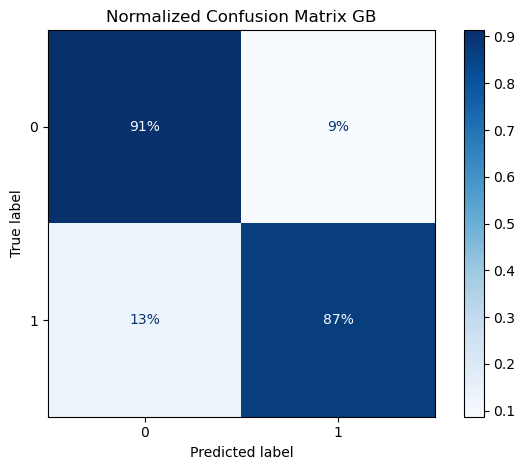

In [769]:
from sklearn.metrics import ConfusionMatrixDisplay

# Predict on the test set
y_test_pred = best_model.predict(X_test)

# Plot the normalized confusion matrix as percentages
ConfusionMatrixDisplay.from_predictions(
    y_test, y_test_pred,
    normalize='true',         # Normalize rows (true labels)
    values_format='.0%',      # Show percentages
    cmap='Blues'              # Optional: nicer color map
)

plt.title('Normalized Confusion Matrix GB')
plt.tight_layout()
plt.savefig('confusion_matrix.png')  # Optional: save it
plt.show()


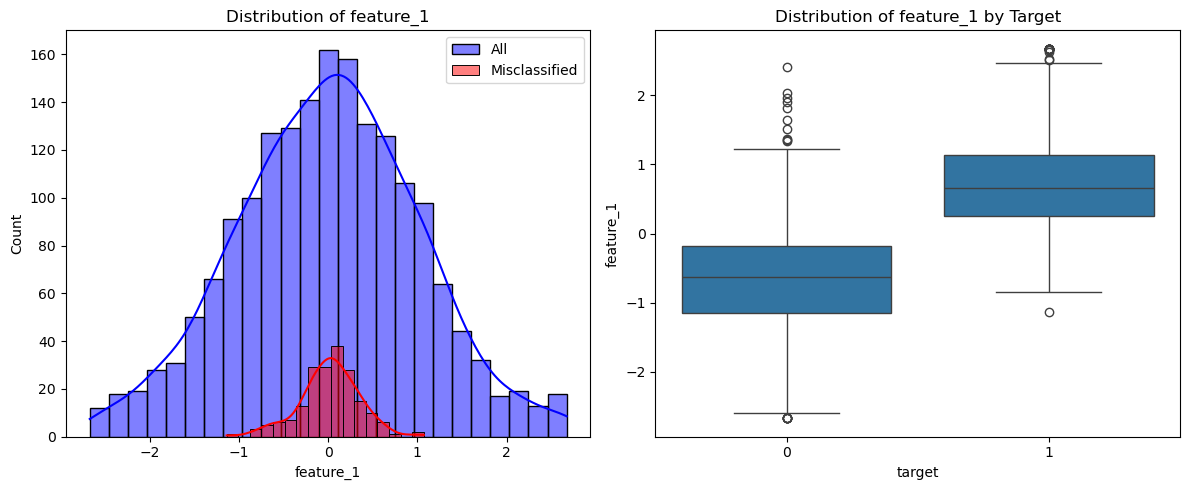

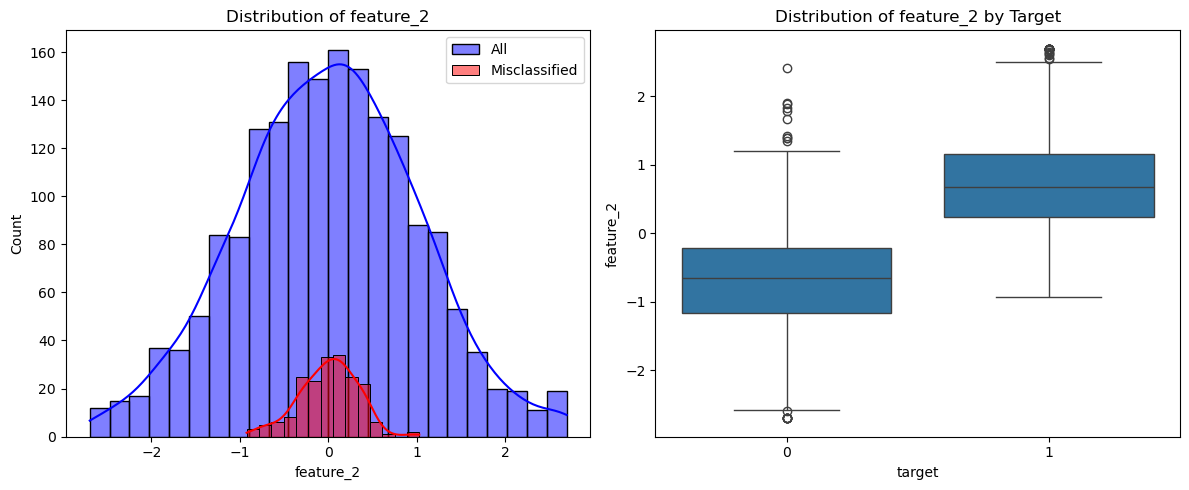

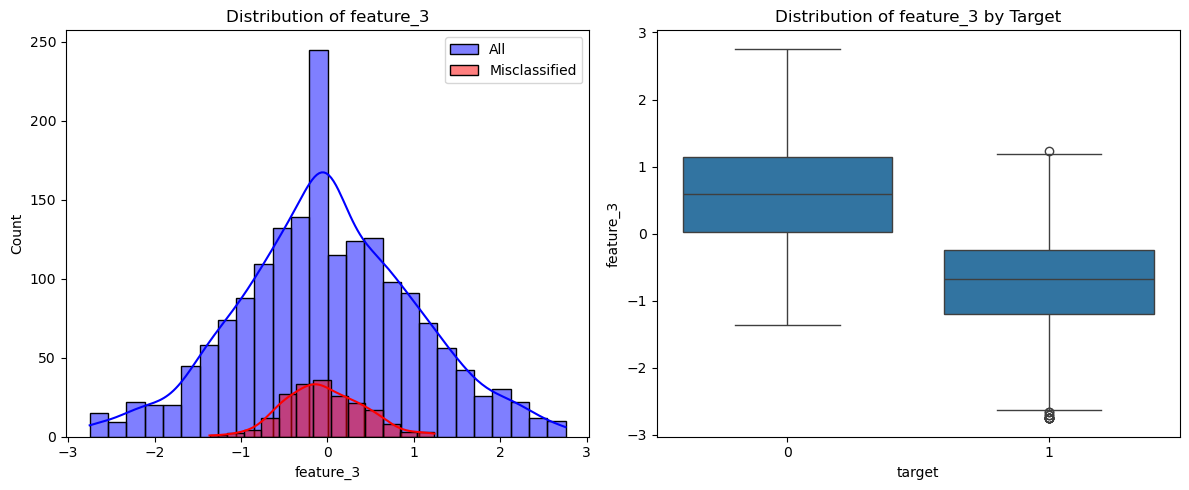

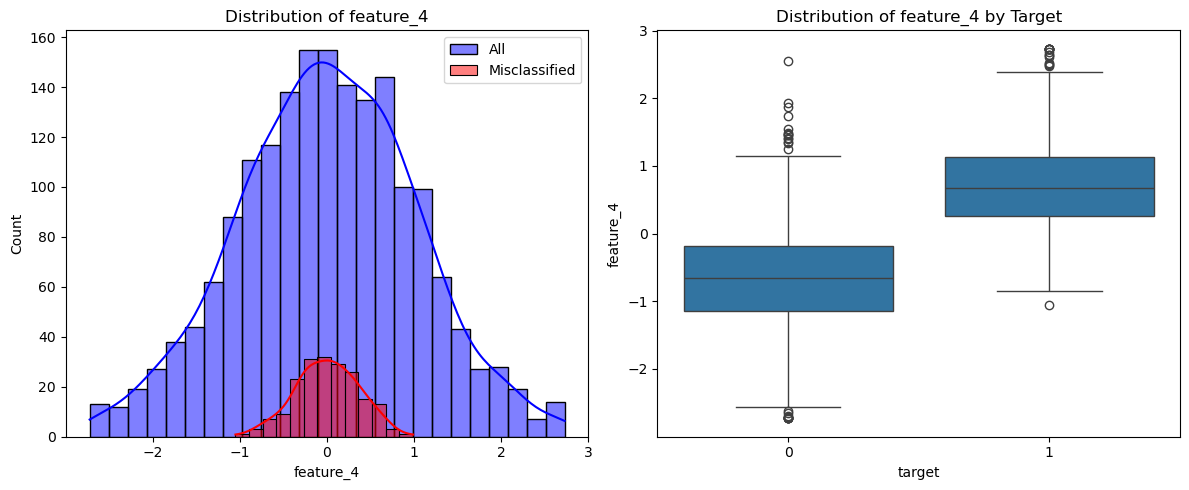

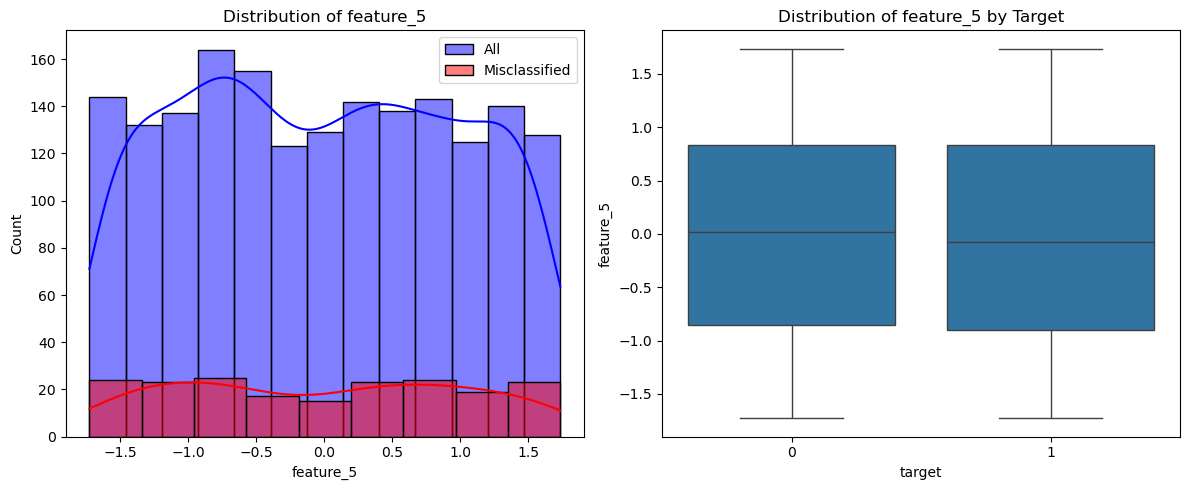

In [763]:
# Distribution of features in misclassified samples
if len(misclassified) > 0:
    for feature in numerical_features[:5]:  # Top 5 numerical features
        plt.figure(figsize=(12, 5))
        
        plt.subplot(1, 2, 1)
        sns.histplot(X_test[feature], color='blue', label='All', alpha=0.5, kde=True)
        sns.histplot(misclassified[feature], color='red', label='Misclassified', alpha=0.5, kde=True)
        plt.title(f'Distribution of {feature}')
        plt.legend()
        
        plt.subplot(1, 2, 2)
        sns.boxplot(x=y_test, y=X_test[feature])
        plt.title(f'Distribution of {feature} by Target')
        
        plt.tight_layout()
        plt.savefig(f'misclassified_{feature}.png')
        plt.show()

<Figure size 640x480 with 0 Axes>